# Hugoniot Fits: Quartz




In [1]:
%%capture 
## This cell loads the modules, data, and EOS parameters
## capture magic function hides the output; comment out to see diagnostic info during data load
## Run executable notebook for output

%run -i scripts/set_paths
%run -i scripts/load_modules
%run -i scripts/load_silica_data
%run -i scripts/define_mc
%run -i scripts/define_eos
%run -i scripts/calibrate_decaying_shocks.py
%run -i scripts/load_vapor_domes.py
%run -i scripts/load_liquid_model.py
%run -i scripts/load_solid_models.py
#%run -i scripts/hugoniot-calcs.py
%run -i scripts/intersection.py # intersection function
%run -i scripts/odr_models.py # ODR and model functions 
%run -i scripts/set_plotstyle.py # customize matplotlib
%run -i scripts/set_colors.py # custom colors

# this notebook's figure name tag
tag = 'QTZ-'


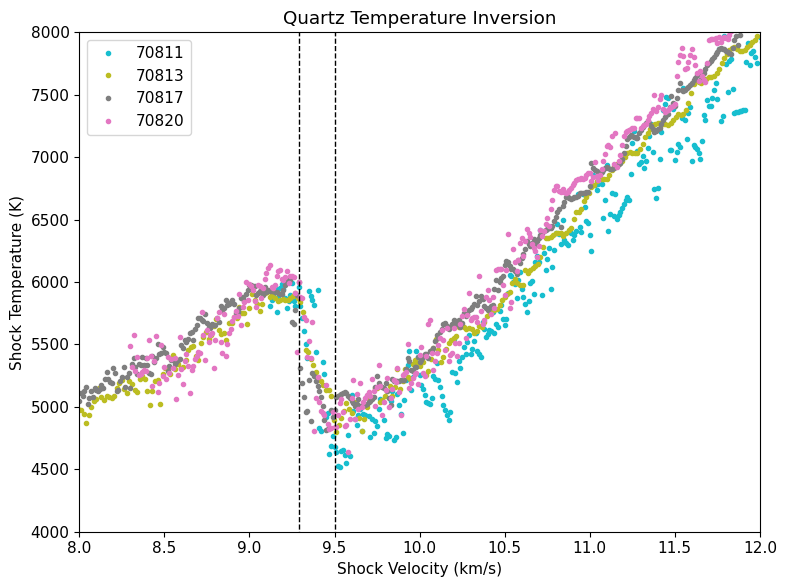

In [2]:
fig, ax = plt.subplots(figsize=fsize)
ax.set_prop_cycle(custom_cycler)
#plt.figure(figsize=fsize)

plt.plot(shockdat_list[MDqtz70811['id']].us,shockdat_list[MDqtz70811['id']].T,'.',label='70811')
plt.plot(shockdat_list[MDqtz70813['id']].us,shockdat_list[MDqtz70813['id']].T,'.',label='70813')
plt.plot(shockdat_list[MDqtz70817['id']].us,shockdat_list[MDqtz70817['id']].T,'.',label='70817')
plt.plot(shockdat_list[MDqtz70820['id']].us,shockdat_list[MDqtz70820['id']].T,'.',label='70820')


plt.xlim(8,12)
plt.ylim(4000,8000)
plt.ylabel('Shock Temperature (K)')
plt.xlabel('Shock Velocity (km/s)')
# qtz_wiggle_us1 and qtz_wiggle_us2 set in define_eos.py
plt.plot([qtz_wiggle_us1,qtz_wiggle_us1],[0,10000],'k--')
plt.plot([qtz_wiggle_us2,qtz_wiggle_us2],[0,10000],'k--')
plt.title('Quartz Temperature Inversion')
plt.legend()
plt.tight_layout()
plt.savefig(outputfigpath+tag+'1-Omega-qtz-Us-T.pdf')
plt.show()


## Evidence for Quartz Hugoniot Melt Curve Crossing

### Using Knudson & Desjarlais 2009 liquid region Hugoniot

First plot the density vs. temperature and derivative using the liquid branch Hugoniot fit from {cite:t}`Knudson2009` for all data points.

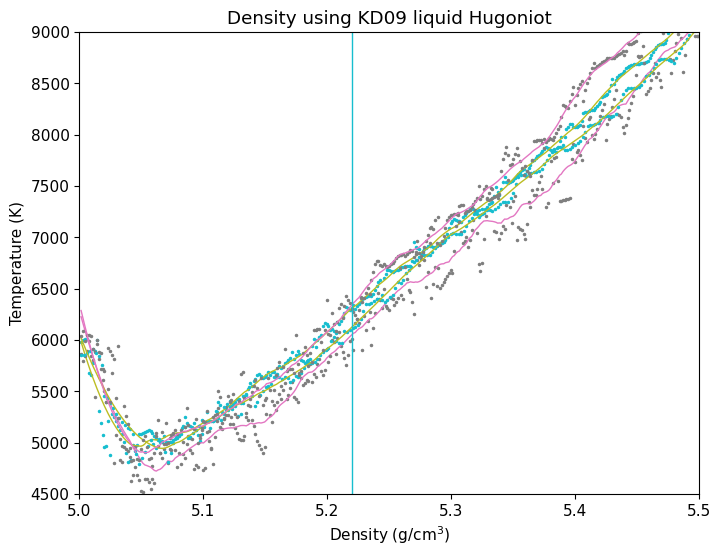

Change in dT/drho at 5.2 g/cm3, corresponds to Us (km/s)= 10.524307923035403
Change in dT/drho at 5.2 g/cm3, corresponds to P (GPa)= 143.93614261127234
Change in dT/drho at 5.2 g/cm3, corresponds to T (K)= 6039.734301156133
Change in dT/drho at 5.28 g/cm3, corresponds to Us (km/s)= 11.081699967461113
Change in dT/drho at 5.28 g/cm3, corresponds to P (GPa)= 162.09905526126101
Change in dT/drho at 5.24 g/cm3, corresponds to Us (km/s)= 10.801236219526364
Change in dT/drho at 5.24 g/cm3, corresponds to P (GPa)= 152.8133659936052
Change in dT/drho at 5.24 g/cm3, corresponds to T (K)= 6406.819752069764
Change in dT/drho at 5.22 g/cm3, corresponds to Us (km/s)= 10.662314844450925
Change in dT/drho at 5.22 g/cm3, corresponds to P (GPa)= 148.3240357095087
Change in dT/drho at 5.22 g/cm3, corresponds to T (K)= 6221.0012069785635


In [3]:
#plt.figure(figsize=fsize)
figure, ax = plt.subplots(figsize=fsize)
ax.set_prop_cycle(custom_cycler)
plt.rcParams['lines.markersize'] = mks
mss=mks/2

# these data 
# first smooth each Omega decaying shock

zzz = np.where((M70817.rho > 5) & (M70817.rho <5.75))[0]
that17 = savgol_filter(M70817.T[zzz], 51, 2) # window size 51, polynomial order 3
zzz17 = deepcopy(zzz)
plt.plot(M70817.rho[zzz],M70817.T[zzz],'.',markersize=mss,label='Omega qtz(z)')
plt.plot(M70817.rho[zzz],that17)


zzz = np.where((M70811.rho > 5) & (M70811.rho <5.75))[0]
that11 = savgol_filter(M70811.T[zzz], 51, 2) # window size 51, polynomial order 3
zzz11 = deepcopy(zzz)
plt.plot(M70811.rho[zzz],M70811.T[zzz],'.',markersize=mss,label='Omega qtz(z)')
plt.plot(M70811.rho[zzz],that11)

zzz = np.where((M70813.rho > 5) & (M70813.rho <5.75))[0]
zzz13 = deepcopy(zzz)
that13 = savgol_filter(M70813.T[zzz], 51, 2) # window size 51, polynomial order 3
plt.plot(M70813.rho[zzz],M70813.T[zzz],'.',markersize=mss,label='Omega qtz(z)')
plt.plot(M70813.rho[zzz],that13)

zzz = np.where((M70820.rho > 5) & (M70820.rho <5.75))[0]
zzz20 = deepcopy(zzz)
that20 = savgol_filter(M70820.T[zzz], 51, 2) # window size 51, polynomial order 3
plt.plot(M70820.rho[zzz],M70820.T[zzz],'.',markersize=mss,label='Omega qtz(z)')
plt.plot(M70820.rho[zzz],that20)


#plt.plot([5.06,5.06],[4000,10000])
#plt.plot([5,5.6],[6700,6700])
#plt.plot([5,5.6],[5900,5900])
#plt.plot([5.1,5.1],[4000,10000])

plt.plot([5.22,5.22],[4000,10000])
#plt.plot([5.23,5.23],[4000,10000])
#plt.plot([5.28,5.28],[4000,10000])
plt.ylim(4500,9000)
plt.xlim(5.,5.5)
plt.xlabel(r'Density (g/cm$^3$)')
plt.ylabel('Temperature (K)')
plt.title('Density using KD09 liquid Hugoniot')
plt.show()

if 1:
    print('Change in dT/drho at 5.2 g/cm3, corresponds to Us (km/s)=',np.interp(5.2,qtz_hug_liq.rho,qtz_hug_liq.us))
    print('Change in dT/drho at 5.2 g/cm3, corresponds to P (GPa)=',np.interp(5.2,qtz_hug_liq.rho,qtz_hug_liq.P))
    print('Change in dT/drho at 5.2 g/cm3, corresponds to T (K)=',np.interp(5.2,qtz_hug_liq.rho,qtz_hug_liq.T))
    print('Change in dT/drho at 5.28 g/cm3, corresponds to Us (km/s)=',np.interp(5.28,qtz_hug_liq.rho,qtz_hug_liq.us))
    print('Change in dT/drho at 5.28 g/cm3, corresponds to P (GPa)=',np.interp(5.28,qtz_hug_liq.rho,qtz_hug_liq.P))
    print('Change in dT/drho at 5.24 g/cm3, corresponds to Us (km/s)=',np.interp(5.24,qtz_hug_liq.rho,qtz_hug_liq.us))
    print('Change in dT/drho at 5.24 g/cm3, corresponds to P (GPa)=',np.interp(5.24,qtz_hug_liq.rho,qtz_hug_liq.P))
    print('Change in dT/drho at 5.24 g/cm3, corresponds to T (K)=',np.interp(5.24,qtz_hug_liq.rho,qtz_hug_liq.T))
    print('Change in dT/drho at 5.22 g/cm3, corresponds to Us (km/s)=',np.interp(5.22,qtz_hug_liq.rho,qtz_hug_liq.us))
    print('Change in dT/drho at 5.22 g/cm3, corresponds to P (GPa)=',np.interp(5.22,qtz_hug_liq.rho,qtz_hug_liq.P))
    print('Change in dT/drho at 5.22 g/cm3, corresponds to T (K)=',np.interp(5.22,qtz_hug_liq.rho,qtz_hug_liq.T))



```{figure} ./figs/dot.png
---
width: 1px
name: dtdrho-1
---
Slope of temperature vs. density in the Omega decaying shock data in quartz converting assuming all in the liquid field. Note the offset at a density of 5.2 g/cm$^3$, corresponding to Us=10.4 km/s. The change in slope indicates a change in heat capacity from the assumed model. The lower density region appears to have approximately half the change in temperature with change in density.
```

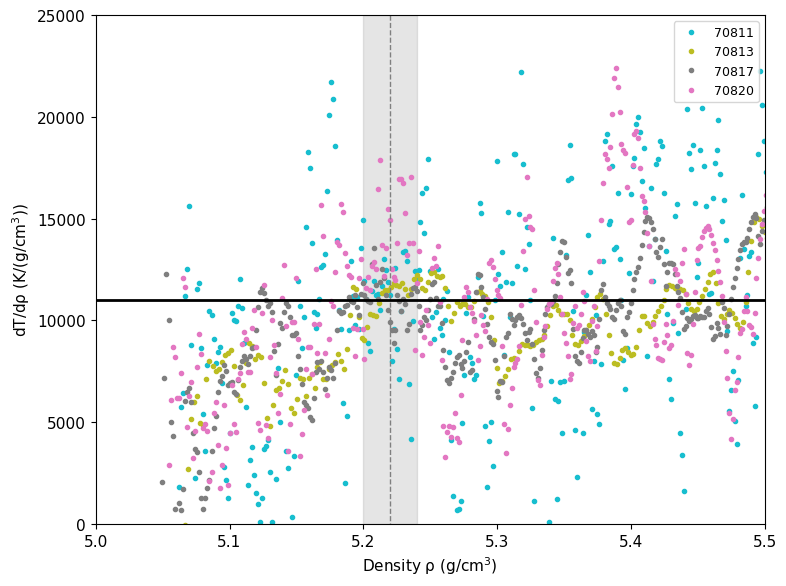

In [4]:
#plt.figure(figsize=fsize)
figure, ax = plt.subplots(figsize=fsize)
ax.set_prop_cycle(custom_cycler)
plt.plot(M70811.rho[zzz11],np.gradient(that11,M70811.rho[zzz11]),'.',label='70811')
plt.plot(M70813.rho[zzz13],np.gradient(that13,M70813.rho[zzz13]),'.',label='70813')
plt.plot(M70817.rho[zzz17],np.gradient(that17,M70817.rho[zzz17]),'.',label='70817')
plt.plot(M70820.rho[zzz20],np.gradient(that20,M70820.rho[zzz20]),'.',label='70820')

#plt.plot([5.06,5.06],[-3e4,3e4])
#plt.plot([5.1,5.1],[-3e4,3e4])
#plt.plot([5.2,5.2],[-3e4,3e4],'--',color='grey')
plt.plot([5.22,5.22],[-3e4,3e4],'--',color='grey')
#plt.plot([5.23,5.23],[-3e4,3e4],'--',color='grey')
plt.fill_between([5.2,5.24],[0,0],[25000,25000],color='grey',alpha=0.2)
plt.plot([5,5.7],[1.1e4,1.1e4],'k-',linewidth=2)
plt.ylim(0,2.5e4)
plt.xlim(5.,5.5)
#plt.title('Slope of T vs. rho (KD09 liquid Hugoniot)')
plt.xlabel(r'Density ρ (g/cm$^3$)')
plt.ylabel('dT/dρ (K/(g/cm$^3$))')
plt.legend(fontsize=lfss)
plt.tight_layout()
plt.savefig(outputfigpath+tag+'B-omega-kink.pdf')
plt.show()


```{figure} ./figs/dot.png
---
width: 1px
name: dtdrho-2
---
Slope of temperature vs. density in the Omega decaying shock data in quartz converting assuming all in the liquid field. Note the offset at a density of 5.2 g/cm$^3$, corresponding to Us=10.6 km/s. The change in slope indicates a change in heat capacity from the assumed model. The lower density region appears to have approximately half the change in temperature with change in density.
```

## Us-up Fits

Do not use Amodeo shot numbers 44 or 28. These are fitted for shock states.

Do not use shot 27 - this has a multi-wave structure.

['shot14' 'shot45' 'shot47' 'shot48']
NEW UCD cacl2 fit [0 6 7 8] [3.89976088 4.45071699 4.28110121 3.7721416 ] [8.46   9.317  9.032  8.2994]
NEW K13 cacl2 fit [0 1 2 3 4 5] [4.01998145 4.02241575 4.02817136 4.29605353 4.57151152 4.59792034] [8.65 8.71 8.75 9.25 9.69 9.72]
Stv region Wackerle + Amodeo all single wave data
['shot27']
HPEOS T-Us FIT STV REGION
FIT EOS a =  [1.52569548 1.7767883 ]
FIT EOS cov =  [[ 0.04325045 -0.01350526]
 [-0.01350526  0.00425656]]
Saved EOS fit in qtz_fit_stv_linear.txt
Saved EOS fit in readable file qtz_fit_stv_linear-readable.txt
rms =  0.06548426167295733
qtz_fit_stv check:
Coefficients are the same.
[1.52569548 1.7767883 ]
[1.52569548 1.7767883 ]
>70 GPa region Knudsen + Amodeo + 1 Boslough + Wackerle z-cut and below solidus
['shot14' 'shot47' 'shot48']
indw= [ 0  1  2  3  4  5  6  7  8  9 10]
[3.89976088 4.28110121 3.7721416 ]
HPEOS T-Us FIT SOLID SINGLE WAVEFRONT REGION P>70 GPa, Us>=7.76 km/s
FIT EOS a =  [1.45201539 1.810208  ]
FIT EOS cov =  [[

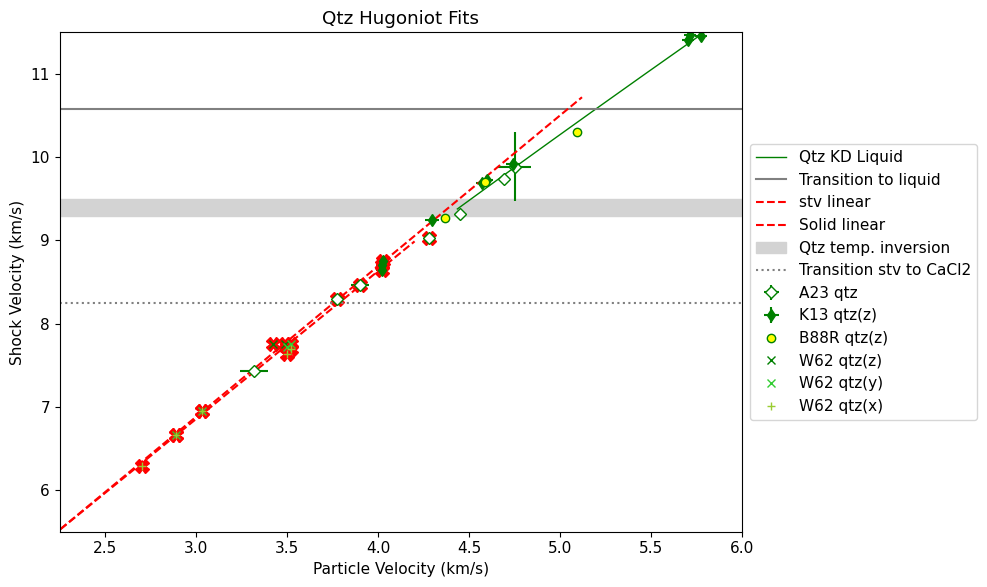

['shot27' 'shot28' 'shot44']


In [5]:
# ODR FITS HERE: STV and CACL2 separately


# CLEAN UP FITS PLOT
fig = plt.figure(figsize=(10, 6))

ind = np.where(qtz_hug_liq.P>110)[0]
plt.plot(qtz_hug_liq.up[ind],qtz_hug_liq.us[ind],'g-',linewidth=1,label='Qtz KD Liquid')
plt.plot([0,20],[qtz_startliq_us,qtz_startliq_us],'-',color='grey',label='Transition to liquid')

inda = np.where((shockdat_list[A23qtz['id']].exp_id != 'shot44') & (shockdat_list[A23qtz['id']].exp_id != 'shot28'))[0]
plt.errorbar(shockdat_list[A23qtz['id']].up[inda],shockdat_list[A23qtz['id']].us[inda],fmt='gD',mfc='white',label=A23qtz['lab'],\
            xerr=shockdat_list[A23qtz['id']].up_std[inda],yerr=shockdat_list[A23qtz['id']].us_std[inda])

plt.errorbar(shockdat_list[K13qtz['id']].up,shockdat_list[K13qtz['id']].us,fmt='gd',markersize=6,\
             xerr=shockdat_list[K13qtz['id']].up_std,yerr=shockdat_list[K13qtz['id']].us_std,label=K13qtz['lab']+'(z)')

ind = np.where(shockdat_list[B88RRqtz['id']].orientation == 'z')[0]#[1:3]
plt.errorbar(shockdat_list[B88RRqtz['id']].up[ind],shockdat_list[B88RRqtz['id']].us[ind],fmt='go',mfc='yellow',\
             label=B88RRqtz['lab']+'(z)')

ind = np.where(shockdat_list[W62qtz['id']].orientation==' z')[0]
plt.errorbar(shockdat_list[W62qtz['id']].up[ind],shockdat_list[W62qtz['id']].us[ind],fmt='gx',label=W62qtz['lab']+'(z)')
ind = np.where(shockdat_list[W62qtz['id']].orientation==' y')[0]
plt.errorbar(shockdat_list[W62qtz['id']].up[ind],shockdat_list[W62qtz['id']].us[ind],fmt='x',color='limegreen',label=W62qtz['lab']+'(y)')
ind = np.where(shockdat_list[W62qtz['id']].orientation==' x')[0]
plt.errorbar(shockdat_list[W62qtz['id']].up[ind],shockdat_list[W62qtz['id']].us[ind],fmt='+',color='yellowgreen',label=W62qtz['lab']+'(x)')

    
# Altshuler
#plt.plot([3.13,3.92,6.2],[7.18,8.54,12.01],'s',color='grey',label='A65 qtz(unknown)')

if 1:
    # fit UCD and Z z-cut points only
    ind =  np.where((np.asarray(shockdat_list[A23qtz['id']].up) > 3.6) & (np.asarray(shockdat_list[A23qtz['id']].up) < 4.6) & (shockdat_list[A23qtz['id']].exp_id != 'shot44') & (shockdat_list[A23qtz['id']].exp_id != 'shot28') & (shockdat_list[A23qtz['id']].exp_id != 'shot27'))[0]
    fitupa=np.asarray(shockdat_list[A23qtz['id']].up)[ind]
    fitusa=np.asarray(shockdat_list[A23qtz['id']].us)[ind]
    print(np.asarray(shockdat_list[A23qtz['id']].exp_id)[ind])
    print('NEW UCD cacl2 fit',ind,fitupa,fitusa)
    ind =  np.where((np.asarray(shockdat_list[K13qtz['id']].up) > 3.6) & (np.asarray(shockdat_list[K13qtz['id']].up) < 4.6))[0]
    fitupb=np.asarray(shockdat_list[K13qtz['id']].up)[ind]
    fitusb=np.asarray(shockdat_list[K13qtz['id']].us)[ind]
    print('NEW K13 cacl2 fit',ind,fitupb,fitusb)
    fitup = np.concatenate((fitupa,fitupb))
    fitus = np.concatenate((fitusa,fitusb))
    
if 0:
    print('Stv region Wackerle y-cut data only (4 pts)')
    indb = np.where(shockdat_list[W62qtz['id']].orientation == ' y')[0]
    # only wackerle
    #rescov = np.polyfit(shockdat_list[W62qtz['id']].up[indb],shockdat_list[W62qtz['id']].us[indb],1,cov=True)
    # Wackerle + 1 altshuler 1965
    fitup = shockdat_list[W62qtz['id']].up[indb]
    fitus = shockdat_list[W62qtz['id']].us[indb]

if 1:
    print('Stv region Wackerle + Amodeo all single wave data')
    inda = np.where((shockdat_list[A23qtz['id']].up<3.6) & (shockdat_list[A23qtz['id']].exp_id != 'shot44') & (shockdat_list[A23qtz['id']].exp_id != 'shot28'))[0]
    print(shockdat_list[A23qtz['id']].exp_id[inda])
    fitupstv1 = [shockdat_list[W62qtz['id']].up,shockdat_list[A23qtz['id']].up[inda]]
    fitupstv = np.concatenate([np.atleast_1d(x) for x in fitupstv1])
    fituperrstv1 = [shockdat_list[W62qtz['id']].up_std,shockdat_list[A23qtz['id']].up_std[inda]]
    fituperrstv = np.concatenate([np.atleast_1d(x) for x in fituperrstv1])

    fitusstv1 = [shockdat_list[W62qtz['id']].us,shockdat_list[A23qtz['id']].us[inda]]
    fitusstv = np.concatenate([np.atleast_1d(x) for x in fitusstv1])
    fituserrstv1 = [shockdat_list[W62qtz['id']].us_std,shockdat_list[A23qtz['id']].us_std[inda]]
    fituserrstv = np.concatenate([np.atleast_1d(x) for x in fituserrstv1])

    r1 = np.full(len(shockdat_list[W62qtz['id']].us), shockdat_list[W62qtz['id']].refidlist[1], dtype=int)
    r2 = np.full(len(inda), shockdat_list[A23qtz['id']].refidlist[1], dtype=int)
    fitqtzrefid2 = np.concatenate((r1,r2))
    fitqtzreflist2=[]
    for i in np.unique(fitqtzrefid2):
        fitqtzreflist2.append(str(i)+': '+ref_list[i].reference[0])

    print('HPEOS T-Us FIT STV REGION')
    # initialize the HPeos_Fit class
    qtz_fit_stv = hp.HPeos_Fit()
    qtz_fit_stv.matid = 174
    qtz_fit_stv.material = 'Quartz'
    qtz_fit_stv.formula = 'SiO2'
    qtz_fit_stv.rho_ref = 2.650
    qtz_fit_stv.rho_ref_units = 'g/cm³'
    qtz_fit_stv.x = fitupstv
    qtz_fit_stv.f = fitusstv
    qtz_fit_stv.x_std = fituperrstv
    qtz_fit_stv.f_std = fituserrstv
    qtz_fit_stv.refid = fitqtzrefid2
    qtz_fit_stv.reflist = fitqtzreflist2
    qtz_fit_stv.x_var = 'up'
    qtz_fit_stv.f_var = 'us'
    qtz_fit_stv.x_units = 'km/s'
    qtz_fit_stv.f_units = 'km/s'
    qtz_fit_stv.x_desc = 'Particle Velocity'
    qtz_fit_stv.f_desc = 'Shock Velocity'
    qtz_fit_stv.phase_fit = 'stishovite'
    qtz_fit_stv.remlist.append('Fit to stishovite region on the Hugoniot.')
    qtz_fit_stv.remlist.append('Only including single wave shock data on alpha-quartz: x,y,z cut from Wackerle 1962. z-cut from Amodeo et al. in prep.')
    DateTime_in_ISOFormat = datetime.datetime.now(zoneinfo.ZoneInfo('UTC')).isoformat('T', 'seconds') #
    qtz_fit_stv.actions = [['Sarah T. Stewart','create',DateTime_in_ISOFormat,'new fit']]

    qtz_fit_stv.curvetype = 'linear'
    qtz_fit_stv.outputfitpath = outputfitpath # in load_paths.py
    qtz_fit_stv.filename = 'qtz_fit_stv_linear'
    qtz_fit_stv.fit()
    print('FIT EOS a = ',qtz_fit_stv.a)
    print('FIT EOS cov = ',qtz_fit_stv.cov)
    qtz_fit_stv.savejson()
    qtz_fit_stv.savereadable()
    print('rms = ',qtz_fit_stv.rms)

    print('qtz_fit_stv check:')
    qtz_fit_stv.comparecoefs(qtz_fit_stv0.a)

    nup = np.arange(.8*qtz_fit_stv.xrange[0],1.2*qtz_fit_stv.xrange[1],.04)
    nus = qtz_fit_stv.calcf(nup)
    plt.plot(nup,nus,'r--',label='stv linear')


    if 0:
        resstvinit = np.polyfit(fitupstv,fitusstv,1)
        data = RealData(fitupstv, fitusstv, sx=fituperrstv, sy=fituserrstv)
        odr = ODR(data, linear_model, beta0=resstvinit)  # Initial guess: slope=1, intercept=0
        output=odr.run()
        resstv = output.beta
        covstv = output.cov_beta
        print('STV ODR linear fit = ',resstv)
        print(covstv)
        fitup = np.arange(min(fitupstv),4.5,.01)
        plt.plot(fitup,resstv[1]+resstv[0]*fitup,'g-')
        print('number of points=',len(fitupstv))

if 1:
    print('>70 GPa region Knudsen + Amodeo + 1 Boslough + Wackerle z-cut and below solidus')
    upmax = 4.29
    inda = np.where((shockdat_list[A23qtz['id']].up>3.6) & (shockdat_list[A23qtz['id']].up<upmax) & (shockdat_list[A23qtz['id']].exp_id != 'shot44') & (shockdat_list[A23qtz['id']].exp_id != 'shot28'))[0]
    print(shockdat_list[A23qtz['id']].exp_id[inda])
    indk = np.where((shockdat_list[K13qtz['id']].up>3.6) & (shockdat_list[K13qtz['id']].up<upmax))[0]
    #indb = np.where(shockdat_list[B88RRqtz['id']].orientation == 'z')[0][0]
    indw = np.arange(len(shockdat_list[W62qtz['id']].up))#np.where(shockdat_list[W62qtz['id']].orientation == ' z')[0]
    #print('indb=',indb,shockdat_list[B88RRqtz['id']].up[indb])
    print('indw=',indw)
    print(shockdat_list[A23qtz['id']].up[inda])
    if 0:
        fitupstv1 = [shockdat_list[K13qtz['id']].up[indk],shockdat_list[A23qtz['id']].up[inda]]
        fitupstv = np.concatenate([np.atleast_1d(x) for x in fitupstv1])
        fituperrstv1 = [shockdat_list[K13qtz['id']].up_std[indk],shockdat_list[A23qtz['id']].up_std[inda]]
        fituperrstv = np.concatenate([np.atleast_1d(x) for x in fituperrstv1])
    
        fitusstv1 = [shockdat_list[K13qtz['id']].us[indk],shockdat_list[A23qtz['id']].us[inda]]
        fitusstv = np.concatenate([np.atleast_1d(x) for x in fitusstv1])
        fituserrstv1 = [shockdat_list[K13qtz['id']].us_std[indk],shockdat_list[A23qtz['id']].us_std[inda]]
        fituserrstv = np.concatenate([np.atleast_1d(x) for x in fituserrstv1])

    if 0: # with boslough
        fitupstv1 = [shockdat_list[K13qtz['id']].up[indk],shockdat_list[A23qtz['id']].up[inda],shockdat_list[B88RRqtz['id']].up[indb],shockdat_list[W62qtz['id']].up[indw]]
        fitupstv = np.concatenate([np.atleast_1d(x) for x in fitupstv1])
        fituperrstv1 = [shockdat_list[K13qtz['id']].up_std[indk],shockdat_list[A23qtz['id']].up_std[inda],shockdat_list[B88RRqtz['id']].up_std[indb],shockdat_list[W62qtz['id']].up_std[indw]]
        fituperrstv = np.concatenate([np.atleast_1d(x) for x in fituperrstv1])
    
        fitusstv1 = [shockdat_list[K13qtz['id']].us[indk],shockdat_list[A23qtz['id']].us[inda],shockdat_list[B88RRqtz['id']].us[indb],shockdat_list[W62qtz['id']].us[indw]]
        fitusstv = np.concatenate([np.atleast_1d(x) for x in fitusstv1])
        fituserrstv1 = [shockdat_list[K13qtz['id']].us_std[indk],shockdat_list[A23qtz['id']].us_std[inda],shockdat_list[B88RRqtz['id']].us_std[indb],shockdat_list[W62qtz['id']].us_std[indw]]
        fituserrstv = np.concatenate([np.atleast_1d(x) for x in fituserrstv1])

    fitupstv1 = [shockdat_list[K13qtz['id']].up[indk],shockdat_list[A23qtz['id']].up[inda],shockdat_list[W62qtz['id']].up[indw]]
    fitupstv = np.concatenate([np.atleast_1d(x) for x in fitupstv1])
    fituperrstv1 = [shockdat_list[K13qtz['id']].up_std[indk],shockdat_list[A23qtz['id']].up_std[inda],shockdat_list[W62qtz['id']].up_std[indw]]
    fituperrstv = np.concatenate([np.atleast_1d(x) for x in fituperrstv1])

    fitusstv1 = [shockdat_list[K13qtz['id']].us[indk],shockdat_list[A23qtz['id']].us[inda],shockdat_list[W62qtz['id']].us[indw]]
    fitusstv = np.concatenate([np.atleast_1d(x) for x in fitusstv1])
    fituserrstv1 = [shockdat_list[K13qtz['id']].us_std[indk],shockdat_list[A23qtz['id']].us_std[inda],shockdat_list[W62qtz['id']].us_std[indw]]
    fituserrstv = np.concatenate([np.atleast_1d(x) for x in fituserrstv1])

    r1 = np.full(len(indk), shockdat_list[K13qtz['id']].refidlist[1], dtype=int)
    r2 = np.full(len(inda), shockdat_list[A23qtz['id']].refidlist[1], dtype=int)
    #r3 = np.full(1, shockdat_list[B88RRqtz['id']].refidlist[1], dtype=int)
    r4 = np.full(len(indw), shockdat_list[W62qtz['id']].refidlist[1], dtype=int)
    fitqtzrefid2 = np.concatenate((r1,r2,r4))
    fitqtzreflist2=[]
    for i in np.unique(fitqtzrefid2):
        fitqtzreflist2.append(str(i)+': '+ref_list[i].reference[0])

    print('HPEOS T-Us FIT SOLID SINGLE WAVEFRONT REGION P>70 GPa, Us>=7.76 km/s')
    # initialize the HPeos_Fit class
    qtz_fit_cacl2 = hp.HPeos_Fit()
    qtz_fit_cacl2.matid = 174
    qtz_fit_cacl2.material = 'Quartz'
    qtz_fit_cacl2.formula = 'SiO2'
    qtz_fit_cacl2.rho_ref = 2.650
    qtz_fit_cacl2.rho_ref_units = 'g/cm³'
    qtz_fit_cacl2.x = fitupstv
    qtz_fit_cacl2.f = fitusstv
    qtz_fit_cacl2.x_std = fituperrstv
    qtz_fit_cacl2.f_std = fituserrstv
    qtz_fit_cacl2.refid = fitqtzrefid2
    qtz_fit_cacl2.reflist = fitqtzreflist2
    qtz_fit_cacl2.x_var = 'up'
    qtz_fit_cacl2.f_var = 'us'
    qtz_fit_cacl2.x_units = 'km/s'
    qtz_fit_cacl2.f_units = 'km/s'
    qtz_fit_cacl2.x_desc = 'Particle Velocity'
    qtz_fit_cacl2.f_desc = 'Shock Velocity'
    qtz_fit_cacl2.phase_fit = 'CaCl2'
    qtz_fit_cacl2.remlist.append('Fit to CaCl2-type region on the Hugoniot.')
    qtz_fit_cacl2.remlist.append('Only including single wave shock data on alpha-quartz: x,y,z cut from Wackerle 1962. z-cut from Amodeo et al. in prep.')
    DateTime_in_ISOFormat = datetime.datetime.now(zoneinfo.ZoneInfo('UTC')).isoformat('T', 'seconds') #
    qtz_fit_cacl2.actions = [['Sarah T. Stewart','create',DateTime_in_ISOFormat,'new fit']]

    qtz_fit_cacl2.curvetype = 'linear'
    qtz_fit_cacl2.outputfitpath = outputfitpath # in load_paths.py
    qtz_fit_cacl2.filename = 'qtz_fit_cacl2_linear'
    qtz_fit_cacl2.fit()
    print('FIT EOS a = ',qtz_fit_cacl2.a)
    print('FIT EOS cov = ',qtz_fit_cacl2.cov)
    qtz_fit_cacl2.savejson()
    qtz_fit_cacl2.savereadable()
    print('rms = ',qtz_fit_cacl2.rms)

    print('qtz_fit_cacl2 check:')
    qtz_fit_cacl2.comparecoefs(qtz_fit_cacl20.a)

    nup = np.arange(.8*qtz_fit_cacl2.xrange[0],1.2*qtz_fit_cacl2.xrange[1],.04)
    nus = qtz_fit_cacl2.calcf(nup)
    plt.plot(fitupstv,fitusstv,'rX',markersize=10)
    plt.plot(nup,nus,'r--',label='Solid linear')

    if 0:
        resstvinit = np.polyfit(fitupstv,fitusstv,1)
        data = RealData(fitupstv, fitusstv, sx=fituperrstv, sy=fituserrstv)
        odr = ODR(data, linear_model, beta0=resstvinit)  # Initial guess: slope=1, intercept=0
        output=odr.run()
        resstv = output.beta
        covstv = output.cov_beta
        print('CACL2 ODR linear fit = ',resstv)
        print(covstv)
        fitup = np.arange(min(fitupstv),5.5,.01)
        plt.plot(fitup,resstv[1]+resstv[0]*fitup,'b:')
        print('number of points=',len(fitupstv))

if 0:
    print('CACL2 + MC region Knudsen + Amodeo + Boslough')
    inda = np.where((shockdat_list[A23qtz['id']].up>3.6) & (shockdat_list[A23qtz['id']].up<5.5) & (shockdat_list[A23qtz['id']].exp_id != 'shot44') & (shockdat_list[A23qtz['id']].exp_id != 'shot28'))[0]
    print(shockdat_list[A23qtz['id']].exp_id[inda])
    indk = np.where((shockdat_list[K13qtz['id']].up>3.6) & (shockdat_list[K13qtz['id']].up<5.5))[0]
    indb = np.where(shockdat_list[B88RRqtz['id']].orientation == 'z')[0][0:3]
    #print(np.asarray(shockdat_list[B88RRqtz['id']].exp_id)[indb])
    print(indb)
    fitupstv1 = [shockdat_list[K13qtz['id']].up[indk],shockdat_list[A23qtz['id']].up[inda],shockdat_list[B88RRqtz['id']].up[indb]]
    fitupstv = np.concatenate([np.atleast_1d(x) for x in fitupstv1])
    fituperrstv1 = [shockdat_list[K13qtz['id']].up_std[indk],shockdat_list[A23qtz['id']].up_std[inda],shockdat_list[B88RRqtz['id']].up_std[indb]]
    fituperrstv = np.concatenate([np.atleast_1d(x) for x in fituperrstv1])

    fitusstv1 = [shockdat_list[K13qtz['id']].us[indk],shockdat_list[A23qtz['id']].us[inda],shockdat_list[B88RRqtz['id']].us[indb]]
    fitusstv = np.concatenate([np.atleast_1d(x) for x in fitusstv1])
    fituserrstv1 = [shockdat_list[K13qtz['id']].us_std[indk],shockdat_list[A23qtz['id']].us_std[inda],shockdat_list[B88RRqtz['id']].us_std[indb]]
    fituserrstv = np.concatenate([np.atleast_1d(x) for x in fituserrstv1])

    print(fitupstv,fitusstv)
    
    resstvinit = np.polyfit(fitupstv,fitusstv,1)
    data = RealData(fitupstv, fitusstv, sx=fituperrstv, sy=fituserrstv)
    odr = ODR(data, linear_model, beta0=resstvinit)  # Initial guess: slope=1, intercept=0
    output=odr.run()
    resstv = output.beta
    covstv = output.cov_beta
    print('CACL2 + MC ODR linear fit = ',resstv)
    print(covstv)
    fitup = np.arange(min(fitupstv),5.5,.01)
    plt.plot(fitup,resstv[1]+resstv[0]*fitup,'g:')
    print('number of points=',len(fitupstv))


plt.fill_between([0,20],[qtz_wiggle_us1,qtz_wiggle_us1],[qtz_wiggle_us2,qtz_wiggle_us2],color='lightgrey',label='Qtz temp. inversion')
plt.plot([0,20],[qtz_trans_cacl2_us,qtz_trans_cacl2_us],':',color='grey',label='Transition stv to CaCl2')
plt.ylim(5.5,11.5)
plt.xlim(2.25,6.)

plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))

#plt.plot(fitup3,fitus3,'g:')
#plt.plot(fitup2,fitus2,'r:')

plt.xlabel('Particle Velocity (km/s)')
plt.ylabel('Shock Velocity (km/s)')
plt.title('Qtz Hugoniot Fits')

figname='H5-qtz-us-up'
plt.tight_layout()
plt.savefig(outputfigpath+figname+'.pdf')
plt.show()


ind = np.where(shockdat_list[A23qtz['id']].up<3.6)[0]
print(shockdat_list[A23qtz['id']].exp_id[ind])

ALL Solid region Knudsen + Amodeo + 1 Boslough + Wackerle 
['shot14' 'shot45' 'shot47' 'shot48']
inda= [0 6 7 8]
indk= [0 1 2 3]
indw= [ 0  1  2  3  4  5  6  7  8  9 10]
HPEOS T-Us FIT CACL2 REGION
FIT EOS a =  [1.96905488 1.66507746]
FIT EOS cov =  [[ 0.00443011 -0.00112652]
 [-0.00112652  0.00028981]]
Saved EOS fit in qtz_fit_solid_linear.txt
Saved EOS fit in readable file qtz_fit_solid_linear-readable.txt
rms =  0.0944169448410331
qtz_fit_solid check:


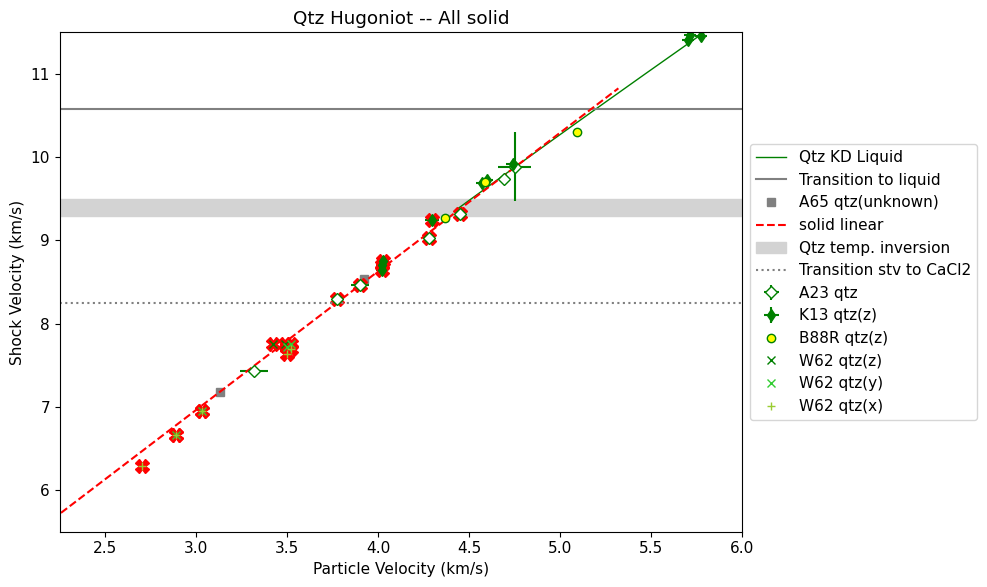

['shot27' 'shot28' 'shot44']


In [6]:
# FIT ALL SOLID WITH ONE Us-Up z-cut only


# CLEAN UP FITS PLOT
fig = plt.figure(figsize=(10, 6))

ind = np.where(qtz_hug_liq.P>110)[0]
plt.plot(qtz_hug_liq.up[ind],qtz_hug_liq.us[ind],'g-',linewidth=1,label='Qtz KD Liquid')
plt.plot([0,20],[qtz_startliq_us,qtz_startliq_us],'-',color='grey',label='Transition to liquid')

inda = np.where((shockdat_list[A23qtz['id']].exp_id != 'shot44') & (shockdat_list[A23qtz['id']].exp_id != 'shot28'))[0]
plt.errorbar(shockdat_list[A23qtz['id']].up[inda],shockdat_list[A23qtz['id']].us[inda],fmt='gD',mfc='white',label=A23qtz['lab'],\
            xerr=shockdat_list[A23qtz['id']].up_std[inda],yerr=shockdat_list[A23qtz['id']].us_std[inda])

plt.errorbar(shockdat_list[K13qtz['id']].up,shockdat_list[K13qtz['id']].us,fmt='gd',markersize=6,\
             xerr=shockdat_list[K13qtz['id']].up_std,yerr=shockdat_list[K13qtz['id']].us_std,label=K13qtz['lab']+'(z)')

ind = np.where(shockdat_list[B88RRqtz['id']].orientation == 'z')[0]#[1:3]
plt.errorbar(shockdat_list[B88RRqtz['id']].up[ind],shockdat_list[B88RRqtz['id']].us[ind],fmt='go',mfc='yellow',\
             label=B88RRqtz['lab']+'(z)')

ind = np.where(shockdat_list[W62qtz['id']].orientation==' z')[0]
plt.errorbar(shockdat_list[W62qtz['id']].up[ind],shockdat_list[W62qtz['id']].us[ind],fmt='gx',label=W62qtz['lab']+'(z)')
ind = np.where(shockdat_list[W62qtz['id']].orientation==' y')[0]
plt.errorbar(shockdat_list[W62qtz['id']].up[ind],shockdat_list[W62qtz['id']].us[ind],fmt='x',color='limegreen',label=W62qtz['lab']+'(y)')
ind = np.where(shockdat_list[W62qtz['id']].orientation==' x')[0]
plt.errorbar(shockdat_list[W62qtz['id']].up[ind],shockdat_list[W62qtz['id']].us[ind],fmt='+',color='yellowgreen',label=W62qtz['lab']+'(x)')

    
# Altshuler
plt.plot([3.13,3.92,6.2],[7.18,8.54,12.01],'s',color='grey',label='A65 qtz(unknown)')

if 0:
    # fit UCD and Z z-cut points only
    ind =  np.where((np.asarray(shockdat_list[A23qtz['id']].up) > 3.6) & (np.asarray(shockdat_list[A23qtz['id']].up) < 4.6) & (shockdat_list[A23qtz['id']].exp_id != 'shot44') & (shockdat_list[A23qtz['id']].exp_id != 'shot28'))[0]
    fitupa=np.asarray(shockdat_list[A23qtz['id']].up)[ind]
    fitusa=np.asarray(shockdat_list[A23qtz['id']].us)[ind]
    print(np.asarray(shockdat_list[A23qtz['id']].exp_id)[ind])
    print('NEW UCD cacl2 fit',ind,fitupa,fitusa)
    ind =  np.where((np.asarray(shockdat_list[K13qtz['id']].up) > 3.6) & (np.asarray(shockdat_list[K13qtz['id']].up) < 4.6))[0]
    fitupb=np.asarray(shockdat_list[K13qtz['id']].up)[ind]
    fitusb=np.asarray(shockdat_list[K13qtz['id']].us)[ind]
    print('NEW K13 cacl2 fit',ind,fitupb,fitusb)
    fitup = np.concatenate((fitupa,fitupb))
    fitus = np.concatenate((fitusa,fitusb))
    
if 0:
    print('Stv region Wackerle + Amodeo all single wave data')
    inda = np.where((shockdat_list[A23qtz['id']].up<3.6) & (shockdat_list[A23qtz['id']].exp_id != 'shot44') & (shockdat_list[A23qtz['id']].exp_id != 'shot28'))[0]
    print(shockdat_list[A23qtz['id']].exp_id[inda])
    fitupstv1 = [shockdat_list[W62qtz['id']].up,shockdat_list[A23qtz['id']].up[inda]]
    fitupstv = np.concatenate([np.atleast_1d(x) for x in fitupstv1])
    fituperrstv1 = [shockdat_list[W62qtz['id']].up_std,shockdat_list[A23qtz['id']].up_std[inda]]
    fituperrstv = np.concatenate([np.atleast_1d(x) for x in fituperrstv1])

    fitusstv1 = [shockdat_list[W62qtz['id']].us,shockdat_list[A23qtz['id']].us[inda]]
    fitusstv = np.concatenate([np.atleast_1d(x) for x in fitusstv1])
    fituserrstv1 = [shockdat_list[W62qtz['id']].us_std,shockdat_list[A23qtz['id']].us_std[inda]]
    fituserrstv = np.concatenate([np.atleast_1d(x) for x in fituserrstv1])

    r1 = np.full(len(shockdat_list[W62qtz['id']].us), shockdat_list[W62qtz['id']].refidlist[1], dtype=int)
    r2 = np.full(len(inda), shockdat_list[A23qtz['id']].refidlist[1], dtype=int)
    fitqtzrefid2 = np.concatenate((r1,r2))
    fitqtzreflist2=[]
    for i in np.unique(fitqtzrefid2):
        fitqtzreflist2.append(str(i)+': '+ref_list[i].reference[0])

    print('HPEOS T-Us FIT STV REGION')
    # initialize the HPeos_Fit class
    qtz_fit_stv = hp.HPeos_Fit()
    qtz_fit_stv.matid = 174
    qtz_fit_stv.material = 'Quartz'
    qtz_fit_stv.formula = 'SiO2'
    qtz_fit_stv.rho_ref = 2.650
    qtz_fit_stv.rho_ref_units = 'g/cm³'
    qtz_fit_stv.x = fitupstv
    qtz_fit_stv.f = fitusstv
    qtz_fit_stv.x_std = fituperrstv
    qtz_fit_stv.f_std = fituserrstv
    qtz_fit_stv.refid = fitqtzrefid2
    qtz_fit_stv.reflist = fitqtzreflist2
    qtz_fit_stv.x_var = 'up'
    qtz_fit_stv.f_var = 'us'
    qtz_fit_stv.x_units = 'km/s'
    qtz_fit_stv.f_units = 'km/s'
    qtz_fit_stv.x_desc = 'Particle Velocity'
    qtz_fit_stv.f_desc = 'Shock Velocity'
    qtz_fit_stv.phase_fit = 'stishovite'
    qtz_fit_stv.remlist.append('Fit to stishovite region on the Hugoniot.')
    qtz_fit_stv.remlist.append('Only including single wave shock data on alpha-quartz: x,y,z cut from Wackerle 1962. z-cut from Amodeo et al. in prep.')
    DateTime_in_ISOFormat = datetime.datetime.now(zoneinfo.ZoneInfo('UTC')).isoformat('T', 'seconds') #
    qtz_fit_stv.actions = [['Sarah T. Stewart','create',DateTime_in_ISOFormat,'new fit']]

    qtz_fit_stv.curvetype = 'linear'
    qtz_fit_stv.outputfitpath = outputfitpath # in load_paths.py
    qtz_fit_stv.filename = 'qtz_fit_stv_linear'
    qtz_fit_stv.fit()
    print('FIT EOS a = ',qtz_fit_stv.a)
    print('FIT EOS cov = ',qtz_fit_stv.cov)
    qtz_fit_stv.savejson()
    qtz_fit_stv.savereadable()
    print('rms = ',qtz_fit_stv.rms)

    print('qtz_fit_stv check:')
    qtz_fit_stv.comparecoefs(qtz_fit_stv0.a)

    nup = np.arange(.8*qtz_fit_stv.xrange[0],1.2*qtz_fit_stv.xrange[1],.04)
    nus = qtz_fit_stv.calcf(nup)
    plt.plot(nup,nus,'r--',label='stv linear')


    if 0:
        resstvinit = np.polyfit(fitupstv,fitusstv,1)
        data = RealData(fitupstv, fitusstv, sx=fituperrstv, sy=fituserrstv)
        odr = ODR(data, linear_model, beta0=resstvinit)  # Initial guess: slope=1, intercept=0
        output=odr.run()
        resstv = output.beta
        covstv = output.cov_beta
        print('STV ODR linear fit = ',resstv)
        print(covstv)
        fitup = np.arange(min(fitupstv),4.5,.01)
        plt.plot(fitup,resstv[1]+resstv[0]*fitup,'g-')
        print('number of points=',len(fitupstv))

if 1:
    print('ALL Solid region Knudsen + Amodeo + 1 Boslough + Wackerle ')
    upmax = 4.55 # km/s
    inda = np.where( (shockdat_list[A23qtz['id']].up<upmax) & (shockdat_list[A23qtz['id']].us_std>0) & (shockdat_list[A23qtz['id']].exp_id != 'shot44') & (shockdat_list[A23qtz['id']].exp_id != 'shot28') & (shockdat_list[A23qtz['id']].exp_id != 'shot27'))[0]
    indk = np.where((shockdat_list[K13qtz['id']].up<upmax))[0]
    #indb = np.where((shockdat_list[B88RRqtz['id']].orientation == 'z') & (shockdat_list[B88RRqtz['id']].up<upmax))[0][0]
    indw = np.where(shockdat_list[W62qtz['id']].up<upmax)[0]

    print(shockdat_list[A23qtz['id']].exp_id[inda])
    print('inda=',inda)
    print('indk=',indk)
    #print('indb=',indb)
    print('indw=',indw)

    fitx1 = [shockdat_list[K13qtz['id']].up[indk],shockdat_list[A23qtz['id']].up[inda],shockdat_list[W62qtz['id']].up[indw]]
    fitx = np.concatenate([np.atleast_1d(x) for x in fitx1])
    fitx_std1 = [shockdat_list[K13qtz['id']].up_std[indk],shockdat_list[A23qtz['id']].up_std[inda],shockdat_list[W62qtz['id']].up_std[indw]]
    fitx_std = np.concatenate([np.atleast_1d(x) for x in fitx_std1])

    fity1 = [shockdat_list[K13qtz['id']].us[indk],shockdat_list[A23qtz['id']].us[inda],shockdat_list[W62qtz['id']].us[indw]]
    fity = np.concatenate([np.atleast_1d(x) for x in fity1])
    fity_std1 = [shockdat_list[K13qtz['id']].us_std[indk],shockdat_list[A23qtz['id']].us_std[inda],shockdat_list[W62qtz['id']].us_std[indw]]
    fity_std = np.concatenate([np.atleast_1d(x) for x in fity_std1])

    r1 = np.full(len(indk), shockdat_list[K13qtz['id']].refidlist[1], dtype=int)
    r2 = np.full(len(inda), shockdat_list[A23qtz['id']].refidlist[1], dtype=int)
    #r3 = np.full(1, shockdat_list[B88RRqtz['id']].refidlist[1], dtype=int)
    r4 = np.full(len(indw), shockdat_list[W62qtz['id']].refidlist[1], dtype=int)
    fitqtzrefid2 = np.concatenate((r1,r2,r4))
    fitqtzreflist2=[]
    for i in np.unique(fitqtzrefid2):
        fitqtzreflist2.append(str(i)+': '+ref_list[i].reference[0])

    plt.plot(fitx,fity,'rX',markersize=10)

    print('HPEOS T-Us FIT CACL2 REGION')
    # initialize the HPeos_Fit class
    qtz_fit_solid = hp.HPeos_Fit()
    qtz_fit_solid.matid = 174
    qtz_fit_solid.material = 'Quartz'
    qtz_fit_solid.formula = 'SiO2'
    qtz_fit_solid.rho_ref = 2.650
    qtz_fit_solid.rho_ref_units = 'g/cm³'
    qtz_fit_solid.x = fitx
    qtz_fit_solid.f = fity
    qtz_fit_solid.x_std = fitx_std
    qtz_fit_solid.f_std = fity_std
    qtz_fit_solid.refid = fitqtzrefid2
    qtz_fit_solid.reflist = fitqtzreflist2
    qtz_fit_solid.x_var = 'up'
    qtz_fit_solid.f_var = 'us'
    qtz_fit_solid.x_units = 'km/s'
    qtz_fit_solid.f_units = 'km/s'
    qtz_fit_solid.x_desc = 'Particle Velocity'
    qtz_fit_solid.f_desc = 'Shock Velocity'
    qtz_fit_solid.phase_fit = 'solid'
    qtz_fit_solid.remlist.append('Fit to solid region on the Hugoniot.')
    qtz_fit_solid.remlist.append('Only including single wave shock data on alpha-quartz: x,y,z cut from Wackerle 1962. z-cut from Amodeo et al. in prep.')
    DateTime_in_ISOFormat = datetime.datetime.now(zoneinfo.ZoneInfo('UTC')).isoformat('T', 'seconds') #
    qtz_fit_solid.actions = [['Sarah T. Stewart','create',DateTime_in_ISOFormat,'new fit']]

    qtz_fit_solid.curvetype = 'linear'
    qtz_fit_solid.outputfitpath = outputfitpath # in load_paths.py
    qtz_fit_solid.filename = 'qtz_fit_solid_linear'
    qtz_fit_solid.fit()
    print('FIT EOS a = ',qtz_fit_solid.a)
    print('FIT EOS cov = ',qtz_fit_solid.cov)
    qtz_fit_solid.savejson()
    qtz_fit_solid.savereadable()
    print('rms = ',qtz_fit_solid.rms)

    print('qtz_fit_solid check:')
    #qtz_fit_solid.comparecoefs(qtz_fit_solid0.a)

    nup = np.arange(.8*qtz_fit_solid.xrange[0],1.2*qtz_fit_solid.xrange[1],.04)
    nus = qtz_fit_solid.calcf(nup)
    plt.plot(nup,nus,'r--',label='solid linear')



plt.fill_between([0,20],[qtz_wiggle_us1,qtz_wiggle_us1],[qtz_wiggle_us2,qtz_wiggle_us2],color='lightgrey',label='Qtz temp. inversion')
plt.plot([0,20],[qtz_trans_cacl2_us,qtz_trans_cacl2_us],':',color='grey',label='Transition stv to CaCl2')
plt.ylim(5.5,11.5)
plt.xlim(2.25,6.)

plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))

#plt.plot(fitup3,fitus3,'g:')
#plt.plot(fitup2,fitus2,'r:')

plt.xlabel('Particle Velocity (km/s)')
plt.ylabel('Shock Velocity (km/s)')
plt.title('Qtz Hugoniot -- All solid')

figname='H5-qtz-us-up'
plt.tight_layout()
plt.savefig(outputfigpath+figname+'.pdf')
plt.show()


ind = np.where(shockdat_list[A23qtz['id']].up<3.6)[0]
print(shockdat_list[A23qtz['id']].exp_id[ind])

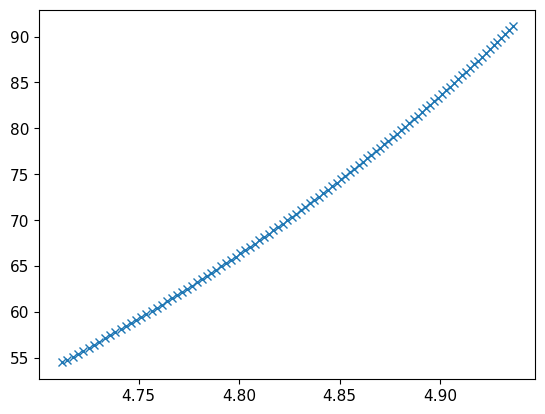

[4.7387883] [57.8388972]
[4.80142893] [66.51156301]
[4.85363197] [74.94746715]
[4.89293053] [82.16082648]
[4.92711089] [89.133893]


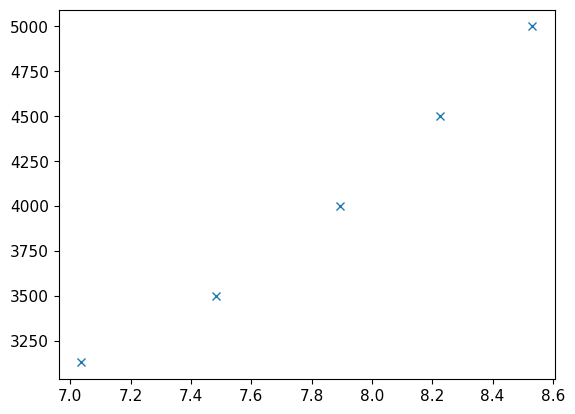

In [7]:
# calculate synthetic temperatures on stv section
# based on P-V shock points + model EOS


tmpup = np.arange(3.,4,.01)
tmpus = qtz_fit_stv0.a[0]+qtz_fit_stv0.a[1]*tmpup
tmpp = 2.65*tmpup*tmpus
tmprho = 1./( (1/2.65)*(1-tmpup/tmpus) )
plt.plot(tmprho,tmpp,'x')
plt.show()
trange = np.asarray([3130,3500,4000,4500,5000])#,5500,5900])
rrange = np.zeros(len(trange))
prange = np.zeros(len(trange))
x,y = intersection(tmprho,tmpp,stvpvt.rhoarr,stvpvt.p3130)
print(x,y)
rrange[0] = x[0]
prange[0] = y[0]
x,y = intersection(tmprho,tmpp,stvpvt.rhoarr,stvpvt.p3500)
print(x,y)
rrange[1] = x[0]
prange[1] = y[0]
x,y = intersection(tmprho,tmpp,stvpvt.rhoarr,stvpvt.p4000)
print(x,y)
rrange[2] = x[0]
prange[2] = y[0]
x,y = intersection(tmprho,tmpp,stvpvt.rhoarr,stvpvt.p4500)
print(x,y)
rrange[3] = x[0]
prange[3] = y[0]
x,y = intersection(tmprho,tmpp,stvpvt.rhoarr,stvpvt.p5000)
print(x,y)
rrange[4] = x[0]
prange[4] = y[0]
#x,y = intersection(tmprho,tmpp,stvpvt.rhoarr,stvpvt.p5500)
#print(x,y)
#rrange[4] = x[0]
#prange[4] = y[0]
#x,y = intersection(tmprho,tmpp,stvpvt.rhoarr,stvpvt.p5900)
#print(x,y)
#rrange[5] = x[0]
#prange[5] = y[0]
usrange = np.interp(prange,tmpp,tmpus)
plt.plot(usrange,trange,'x')
plt.show()
stvusmodel = usrange
stvtmodel = trange
stvpmodel = prange

# save this model for plotting
with open(figurefigpath+'stvmodel.pkl', 'wb') as f:  # Python 3: open(..., 'wb')
    pickle.dump([stvusmodel,stvtmodel,stvpmodel], f)


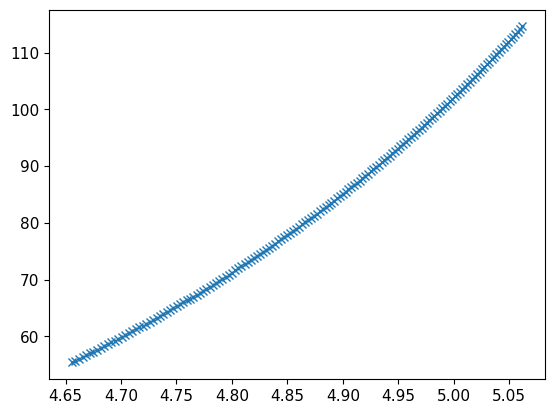

[] []
[] []
[] []
[4.72274249] [62.21453597]
[4.85188782] [78.09284821]
[4.92214492] [88.59747104]
[4.97445964] [97.46522763]
[5.00717586] [103.52737812]


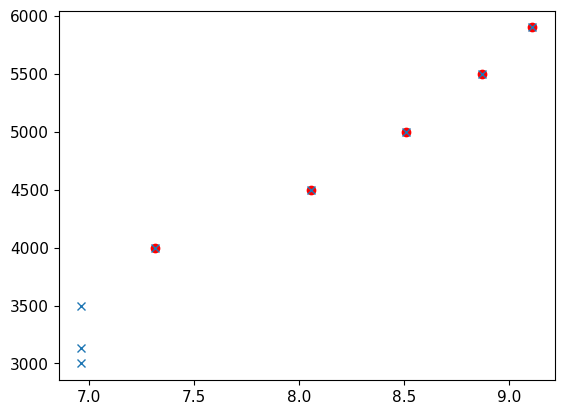

In [8]:
# calculate synthetic temperatures on all solid section
# based on P-V shock points + model EOS


tmpup = np.arange(3.,4.55,.01)
tmpus = qtz_fit_solid0.a[0]+qtz_fit_solid0.a[1]*tmpup
tmpp = 2.65*tmpup*tmpus
tmprho = 1./( (1/2.65)*(1-tmpup/tmpus) )
plt.plot(tmprho,tmpp,'x')
plt.show()
trange = np.asarray([3000.,3130,3500,4000,4500,5000,5500,5900])
rrange = np.zeros(len(trange))
prange = np.zeros(len(trange))
x,y = intersection(tmprho,tmpp,stvpvt.rhoarr,stvpvt.p3000)
print(x,y)
if len(x)>0:
    rrange[0] = x[0]
    prange[0] = y[0]
x,y = intersection(tmprho,tmpp,stvpvt.rhoarr,stvpvt.p3130)
print(x,y)
if len(x)>0:
    rrange[1] = x[0]
    prange[1] = y[0]
x,y = intersection(tmprho,tmpp,stvpvt.rhoarr,stvpvt.p3500)
print(x,y)
if len(x)>0:
    rrange[2] = x[0]
    prange[2] = y[0]
x,y = intersection(tmprho,tmpp,stvpvt.rhoarr,stvpvt.p4000)
print(x,y)
rrange[3] = x[0]
prange[3] = y[0]
x,y = intersection(tmprho,tmpp,stvpvt.rhoarr,stvpvt.p4500)
print(x,y)
rrange[4] = x[0]
prange[4] = y[0]
x,y = intersection(tmprho,tmpp,stvpvt.rhoarr,stvpvt.p5000)
print(x,y)
rrange[5] = x[0]
prange[5] = y[0]
x,y = intersection(tmprho,tmpp,stvpvt.rhoarr,stvpvt.p5500)
print(x,y)
rrange[6] = x[0]
prange[6] = y[0]
x,y = intersection(tmprho,tmpp,stvpvt.rhoarr,stvpvt.p5900)
print(x,y)
rrange[7] = x[0]
prange[7] = y[0]
usrange = np.interp(prange,tmpp,tmpus)
solidusmodel = usrange[3::]
solidtmodel = trange[3::]
plt.plot(solidusmodel,solidtmodel,'ro')
plt.plot(usrange,trange,'x')
plt.show()


[2.61789622 1.50630632]


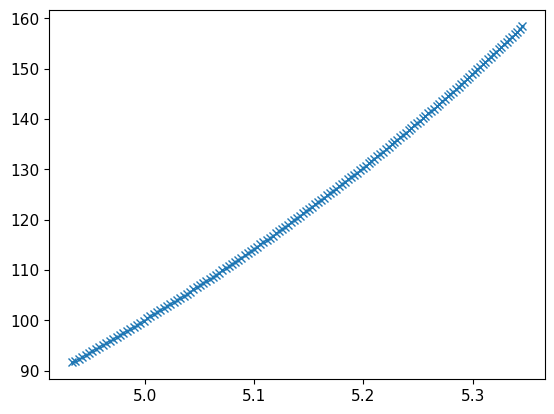

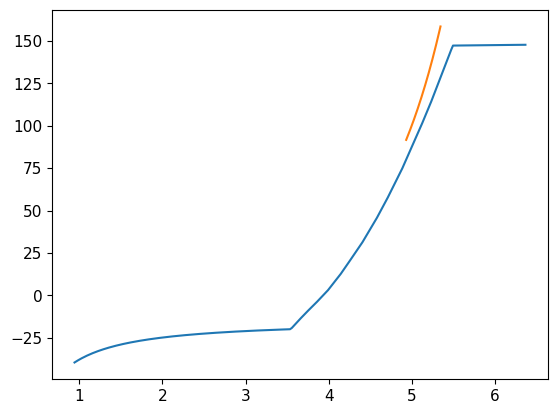

5500 [5.00472333] [100.71216986]
[5.08159436] [111.4700905]
[5.00472333 5.08159436] [100.71216986 111.4700905 ]


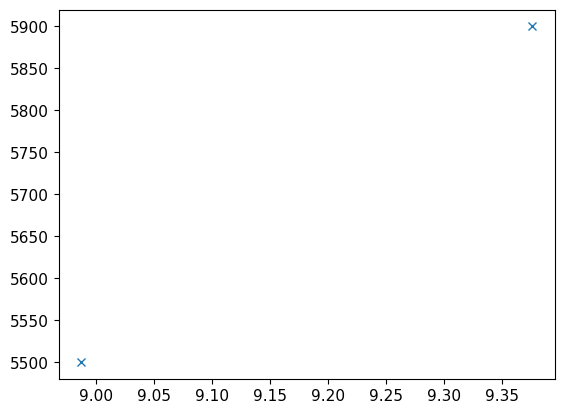

[8.98748154 9.37584595] [5500 5900]


In [9]:
# calculate synthetic temperatures on cacl2 section
# based on P-V shock points + model EOS

print(qtz_fit_cacl20.a)
tmpup = np.arange(4.,5.5,.01)
tmpus = qtz_fit_cacl20.a[0]+qtz_fit_cacl20.a[1]*tmpup
tmpp = 2.65*tmpup*tmpus
tmprho = 1./( (1/2.65)*(1-tmpup/tmpus) )
plt.plot(tmprho,tmpp,'x')
plt.show()
#trange = np.asarray([3500,4000,4500,5000,5500,5900])
trange = np.asarray([5500,5900])
rrange = np.zeros(len(trange))
prange = np.zeros(len(trange))
plt.plot(stvpvt.rhoarr,stvpvt.p3500)
plt.plot(tmprho,tmpp),
plt.show()
if 0:
    x,y = intersection(tmprho,tmpp,stvpvt.rhoarr,stvpvt.p3500)
    print(x,y)
    if len(x) > 1:
        rrange[0] = x[0]
        prange[0] = y[0]
    x,y = intersection(tmprho,tmpp,stvpvt.rhoarr,stvpvt.p4000)
    print(x,y)
    if len(x) > 1:
        rrange[1] = x[0]
        prange[1] = y[0]
    x,y = intersection(tmprho,tmpp,stvpvt.rhoarr,stvpvt.p4500)
    print(x,y)
    if len(x) > 1:
        rrange[2] = x[0]
        prange[2] = y[0]
    x,y = intersection(tmprho,tmpp,stvpvt.rhoarr,stvpvt.p5000)
    print(x,y)
    if len(x) > 1:
        rrange[3] = x[0]
        prange[3] = y[0]
    x,y = intersection(tmprho,tmpp,stvpvt.rhoarr,stvpvt.p5500)
    print(x,y)
    if len(x) > 1:
        rrange[4] = x[0]
        prange[4] = y[0]
    x,y = intersection(tmprho,tmpp,stvpvt.rhoarr,stvpvt.p5900)
    print(x,y)
    if len(x) > 1:
        rrange[5] = x[0]
        prange[5] = y[0]
x,y = intersection(tmprho,tmpp,stvpvt.rhoarr,stvpvt.p5500)
print('5500',x,y)
if len(x) > 0:
    rrange[0] = x[0]
    prange[0] = y[0]
x,y = intersection(tmprho,tmpp,stvpvt.rhoarr,stvpvt.p5900)
print(x,y)
if len(x) > 0:
    rrange[1] = x[0]
    prange[1] = y[0]
print(rrange,prange)
usrange = np.interp(prange,tmpp,tmpus)
plt.plot(usrange,trange,'x')
plt.show()
cacl2usmodel = usrange
cacl2tmodel = trange
print(cacl2usmodel,cacl2tmodel)

CACL2 region Knudsen + Amodeo + 1 Boslough
['shot26' 'shot33']
HPEOS T-Us FIT LIQUID REGION
FIT EOS a =  [ 1.75601795e+00  1.84956245e+00 -3.17458138e-02  4.97145666e-04]
FIT EOS cov =  [[ 1.61128022e-02 -4.71961658e-03  4.27549341e-04 -1.21491728e-05]
 [-4.71961658e-03  1.42389771e-03 -1.31805531e-04  3.80830655e-06]
 [ 4.27549341e-04 -1.31805531e-04  1.24191015e-05 -3.64240673e-07]
 [-1.21491728e-05  3.80830655e-06 -3.64240673e-07  1.08307156e-08]]
Saved EOS fit in qtz_fit_liq_cubic.txt
Saved EOS fit in readable file qtz_fit_liq_cubic-readable.txt
rms =  0.09956970253786962
qtz_fit_liq check:
Coefficients are the same.
[ 1.75601795e+00  1.84956245e+00 -3.17458138e-02  4.97145666e-04]
[ 1.75601795e+00  1.84956245e+00 -3.17458138e-02  4.97145666e-04]
LIQUID ODR cubic fit =  [ 4.97148511e-04 -3.17459054e-02  1.84956335e+00  1.75601530e+00]
[[ 1.08305644e-08 -3.64235245e-07  3.80824434e-06 -1.21489566e-05]
 [-3.64235245e-07  1.24189066e-05 -1.31803295e-04  4.27541552e-04]
 [ 3.80824434e-

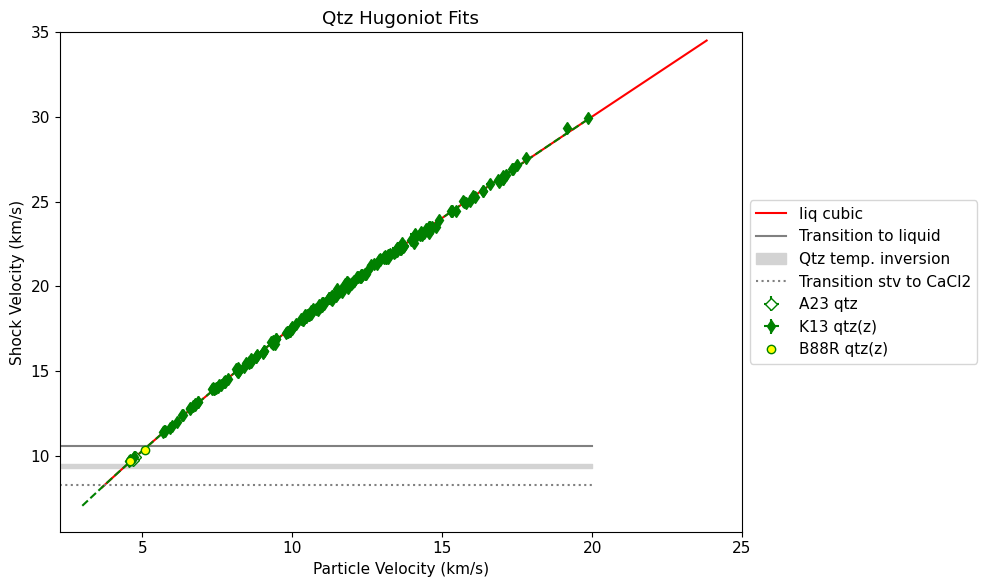

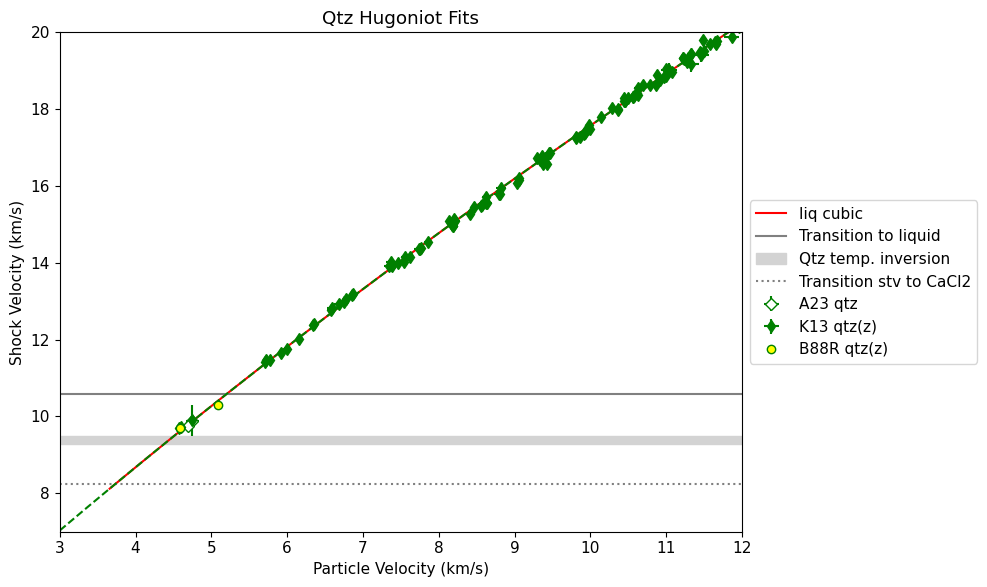

['shot27' 'shot28' 'shot44']


In [10]:
# FIT LIQUID

if 1:
    print('CACL2 region Knudsen + Amodeo + 1 Boslough')
    inda = np.where((shockdat_list[A23qtz['id']].up>3.6) & (shockdat_list[A23qtz['id']].up>4.55) & (shockdat_list[A23qtz['id']].exp_id != 'shot44') & (shockdat_list[A23qtz['id']].exp_id != 'shot28')) [0]
    print(shockdat_list[A23qtz['id']].exp_id[inda])
    indk = np.where((shockdat_list[K13qtz['id']].up>4.55))[0]
    indb = np.where(shockdat_list[B88RRqtz['id']].orientation == 'z')[0][1:3]

    fitupstv1 = [shockdat_list[K13qtz['id']].up[indk],shockdat_list[A23qtz['id']].up[inda],shockdat_list[B88RRqtz['id']].up[indb]]
    fitupstv = np.concatenate([np.atleast_1d(x) for x in fitupstv1])
    fituperrstv1 = [shockdat_list[K13qtz['id']].up_std[indk],shockdat_list[A23qtz['id']].up_std[inda],shockdat_list[B88RRqtz['id']].up_std[indb]]
    fituperrstv = np.concatenate([np.atleast_1d(x) for x in fituperrstv1])

    fitusstv1 = [shockdat_list[K13qtz['id']].us[indk],shockdat_list[A23qtz['id']].us[inda],shockdat_list[B88RRqtz['id']].us[indb]]
    fitusstv = np.concatenate([np.atleast_1d(x) for x in fitusstv1])
    fituserrstv1 = [shockdat_list[K13qtz['id']].us_std[indk],shockdat_list[A23qtz['id']].us_std[inda],shockdat_list[B88RRqtz['id']].us_std[indb]]
    fituserrstv = np.concatenate([np.atleast_1d(x) for x in fituserrstv1])

    r1 = np.full(len(indk), shockdat_list[K13qtz['id']].refidlist[1], dtype=int)
    r2 = np.full(len(inda), shockdat_list[A23qtz['id']].refidlist[1], dtype=int)
    r3 = np.full(len(indb), shockdat_list[B88RRqtz['id']].refidlist[1], dtype=int)
    fitqtzrefid2 = np.concatenate((r1,r2,r3))
    fitqtzreflist2=[]
    for i in np.unique(fitqtzrefid2):
        fitqtzreflist2.append(str(i)+': '+ref_list[i].reference[0])


    # use new fitting system
    print('HPEOS T-Us FIT LIQUID REGION')
    # initialize the HPeos_Fit class
    qtz_fit_liq = hp.HPeos_Fit()
    qtz_fit_liq.matid = 174
    qtz_fit_liq.material = 'Quartz'
    qtz_fit_liq.formula = 'SiO2'
    qtz_fit_liq.rho_ref = 2.650
    qtz_fit_liq.rho_ref_units = 'g/cm³'
    qtz_fit_liq.x = fitupstv
    qtz_fit_liq.f = fitusstv
    qtz_fit_liq.x_std = fituperrstv
    qtz_fit_liq.f_std = fituserrstv
    qtz_fit_liq.refid = fitqtzrefid2
    qtz_fit_liq.reflist = fitqtzreflist2
    qtz_fit_liq.x_var = 'up'
    qtz_fit_liq.f_var = 'us'
    qtz_fit_liq.x_units = 'km/s'
    qtz_fit_liq.f_units = 'km/s'
    qtz_fit_liq.x_desc = 'Particle Velocity'
    qtz_fit_liq.f_desc = 'Shock Velocity'
    qtz_fit_liq.phase_fit = 'liquid'
    qtz_fit_liq.remlist.append('Fit to liquid region on the Hugoniot including the metastable shock fronts below the melt curve.')
    qtz_fit_liq.remlist.append('Only including z-cut alpha-quartz.')
    qtz_fit_liq.remlist.append('Did not include Lyzenga et al. JGR 1983 (refid=285) and Boslough JGR 1988 (refid=300) points that lack impedance match information.')
    DateTime_in_ISOFormat = datetime.datetime.now(zoneinfo.ZoneInfo('UTC')).isoformat('T', 'seconds') #
    qtz_fit_liq.actions = [['Sarah T. Stewart','create',DateTime_in_ISOFormat,'new fit']]

    qtz_fit_liq.curvetype = 'cubic'
    qtz_fit_liq.outputfitpath = outputfitpath # in load_paths.py
    qtz_fit_liq.filename = 'qtz_fit_liq_cubic'
    qtz_fit_liq.fit()
    print('FIT EOS a = ',qtz_fit_liq.a)
    print('FIT EOS cov = ',qtz_fit_liq.cov)
    qtz_fit_liq.savejson()
    qtz_fit_liq.savereadable()
    print('rms = ',qtz_fit_liq.rms)

    print('qtz_fit_liq check:')
    qtz_fit_liq.comparecoefs(qtz_fit_liq0.a)

    nup = np.arange(.8*qtz_fit_liq.xrange[0],1.2*qtz_fit_liq.xrange[1],.04)
    nus = qtz_fit_liq.calcf(nup)
    #plt.plot(nup,nus,'r-',label='liq cubic')
    
    resstvinit = np.polyfit(fitupstv,fitusstv,3)
    data = RealData(fitupstv, fitusstv, sx=fituperrstv, sy=fituserrstv)
    odr = ODR(data, cubic_model, beta0=resstvinit)  # Initial guess: slope=1, intercept=0
    output=odr.run()
    resliq = output.beta
    covliq = output.cov_beta
    print('LIQUID ODR cubic fit = ',resliq)
    print(covliq)
    print('number of points=',len(fitupstv))
    yyy = resliq[3]+resliq[2]*fitupstv + resliq[1]*fitupstv*fitupstv+resliq[0]*fitupstv*fitupstv*fitupstv
    dy = yyy-fitusstv
    rms = np.sqrt(np.mean(dy**2))
    print('ODR cubic rms = ',rms)

    fitup3 = np.arange(3,20,.01)
    fitus3 = resliq[3]+resliq[2]*fitup3 + resliq[1]*fitup3*fitup3+resliq[0]*fitup3*fitup3*fitup3

    
    if 1:
        resstvinit = np.polyfit(fitupstv,fitusstv,2)
        data = RealData(fitupstv, fitusstv, sx=fituperrstv, sy=fituserrstv)
        odr = ODR(data, quadratic_model, beta0=resstvinit)  # Initial guess: slope=1, intercept=0
        output=odr.run()
        resliq = output.beta
        covliq = output.cov_beta
        print('LIQUID ODR quadratic fit = ',resliq)
        print(covliq)
        print('number of points=',len(fitupstv))
        print('min, max up=',min(fitupstv),max(fitupstv))
        yyy = resliq[2]+resliq[1]*fitupstv + resliq[0]*fitupstv*fitupstv #+resliq[0]*fitupstv*fitupstv*fitupstv
        dy = yyy-fitusstv
        rms = np.sqrt(np.mean(dy**2))
        print('ODR quadratic rms = ',rms)
        fitup2 = np.arange(3,20,.01)
        fitus2 = resliq[2]+resliq[1]*fitup2 + resliq[0]*fitup2*fitup2 #+resliq[0]*fitup*fitup*fitup


fig = plt.figure(figsize=(10, 6))
plt.plot(nup,nus,'r-',label='liq cubic')

#ind = np.where(qtz_hug_liq.P>110)[0]
#plt.plot(qtz_hug_liq.up[ind],qtz_hug_liq.us[ind],'g-',linewidth=1,label='Qtz KD Liquid')
plt.plot([0,20],[qtz_startliq_us,qtz_startliq_us],'-',color='grey',label='Transition to liquid')

inda = np.where((shockdat_list[A23qtz['id']].up > 4.55) & (shockdat_list[A23qtz['id']].exp_id != 'shot44') & (shockdat_list[A23qtz['id']].exp_id != 'shot28'))[0]
plt.errorbar(shockdat_list[A23qtz['id']].up[inda],shockdat_list[A23qtz['id']].us[inda],fmt='gD',mfc='white',label=A23qtz['lab'],\
            xerr=shockdat_list[A23qtz['id']].up_std[inda],yerr=shockdat_list[A23qtz['id']].us_std[inda])

indk = np.where((shockdat_list[K13qtz['id']].up > 4.55))[0]
plt.errorbar(shockdat_list[K13qtz['id']].up[indk],shockdat_list[K13qtz['id']].us[indk],fmt='gd',markersize=6,\
             xerr=shockdat_list[K13qtz['id']].up_std[indk],yerr=shockdat_list[K13qtz['id']].us_std[indk],label=K13qtz['lab']+'(z)')

ind = np.where(shockdat_list[B88RRqtz['id']].orientation == 'z')[0][1:3]
plt.errorbar(shockdat_list[B88RRqtz['id']].up[ind],shockdat_list[B88RRqtz['id']].us[ind],fmt='go',mfc='yellow',\
             label=B88RRqtz['lab']+'(z)')

plt.fill_between([0,20],[qtz_wiggle_us1,qtz_wiggle_us1],[qtz_wiggle_us2,qtz_wiggle_us2],color='lightgrey',label='Qtz temp. inversion')
plt.plot([0,20],[qtz_trans_cacl2_us,qtz_trans_cacl2_us],':',color='grey',label='Transition stv to CaCl2')
plt.ylim(5.5,35)
plt.xlim(2.25,25.)

plt.plot(fitup3,fitus3,'g--')
#plt.plot(fitup2,fitus2,'r:')

plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))

plt.xlabel('Particle Velocity (km/s)')
plt.ylabel('Shock Velocity (km/s)')
plt.title('Qtz Hugoniot Fits')

plt.tight_layout()
plt.show()

fig = plt.figure(figsize=(10, 6))
plt.plot(nup,nus,'r-',label='liq cubic')

#ind = np.where(qtz_hug_liq.P>110)[0]
#plt.plot(qtz_hug_liq.up[ind],qtz_hug_liq.us[ind],'g-',linewidth=1,label='Qtz KD Liquid')
plt.plot([0,20],[qtz_startliq_us,qtz_startliq_us],'-',color='grey',label='Transition to liquid')

inda = np.where((shockdat_list[A23qtz['id']].up > 4.55) & (shockdat_list[A23qtz['id']].exp_id != 'shot44') & (shockdat_list[A23qtz['id']].exp_id != 'shot28'))[0]
plt.errorbar(shockdat_list[A23qtz['id']].up[inda],shockdat_list[A23qtz['id']].us[inda],fmt='gD',mfc='white',label=A23qtz['lab'],\
            xerr=shockdat_list[A23qtz['id']].up_std[inda],yerr=shockdat_list[A23qtz['id']].us_std[inda])

indk = np.where((shockdat_list[K13qtz['id']].up > 4.55))[0]
plt.errorbar(shockdat_list[K13qtz['id']].up[indk],shockdat_list[K13qtz['id']].us[indk],fmt='gd',markersize=6,\
             xerr=shockdat_list[K13qtz['id']].up_std[indk],yerr=shockdat_list[K13qtz['id']].us_std[indk],label=K13qtz['lab']+'(z)')

ind = np.where(shockdat_list[B88RRqtz['id']].orientation == 'z')[0][1:3]
plt.errorbar(shockdat_list[B88RRqtz['id']].up[ind],shockdat_list[B88RRqtz['id']].us[ind],fmt='go',mfc='yellow',\
             label=B88RRqtz['lab']+'(z)')

plt.fill_between([0,20],[qtz_wiggle_us1,qtz_wiggle_us1],[qtz_wiggle_us2,qtz_wiggle_us2],color='lightgrey',label='Qtz temp. inversion')
plt.plot([0,20],[qtz_trans_cacl2_us,qtz_trans_cacl2_us],':',color='grey',label='Transition stv to CaCl2')
plt.ylim(7,20)
plt.xlim(3,12.)

#plt.plot(fitup,resliq[3]+resliq[2]*fitup + resliq[1]*fitup*fitup+resliq[0]*fitup*fitup*fitup,'g--')
plt.plot(fitup3,fitus3,'g--')
#plt.plot(fitup2,fitus2,'r:')

plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))

plt.xlabel('Particle Velocity (km/s)')
plt.ylabel('Shock Velocity (km/s)')
plt.title('Qtz Hugoniot Fits')

plt.tight_layout()
plt.show()

ind = np.where(shockdat_list[A23qtz['id']].up<3.6)[0]
print(shockdat_list[A23qtz['id']].exp_id[ind])

In [11]:
print(shockdat_list[K13qtz['id']].rho_std)

[0.04399988 0.04294756 0.04258048 0.04521581 0.04053482 0.04067165
 0.04493477 0.03958338 0.04036226 0.0392091  0.04405252 0.04416386
 0.03911546 0.03913424 0.06183477 0.06161612 0.06176932 0.06277932
 0.04187729 0.04218766 0.04209119 0.06068718 0.04177903 0.04131814
 0.06191412 0.05976167 0.06168581 0.06185488 0.06223706 0.04272386
 0.0418874  0.06207319 0.04010253 0.06129614 0.04076936 0.040968
 0.04039129 0.0419007  0.04256517 0.04007343 0.06236953 0.06016802
 0.06209287 0.04307361 0.06028571 0.04024831 0.03974824 0.04234484
 0.03992009 0.04143564 0.03823234 0.04019343 0.03900231 0.04014377
 0.03937773 0.03778424 0.03979206 0.04038471 0.0407     0.0383296
 0.03894432 0.03874295 0.03825807 0.03811738 0.03857976 0.03953463
 0.03934817 0.04197632 0.0382668  0.03899769 0.03757021 0.03765131
 0.03733253 0.03724436 0.03879025 0.037666   0.03753686 0.03756643
 0.03801967 0.03753409 0.03841731 0.04636603 0.03750568 0.03853735
 0.04581872 0.03786361 0.04010525 0.03877538 0.04135872 0.0395482

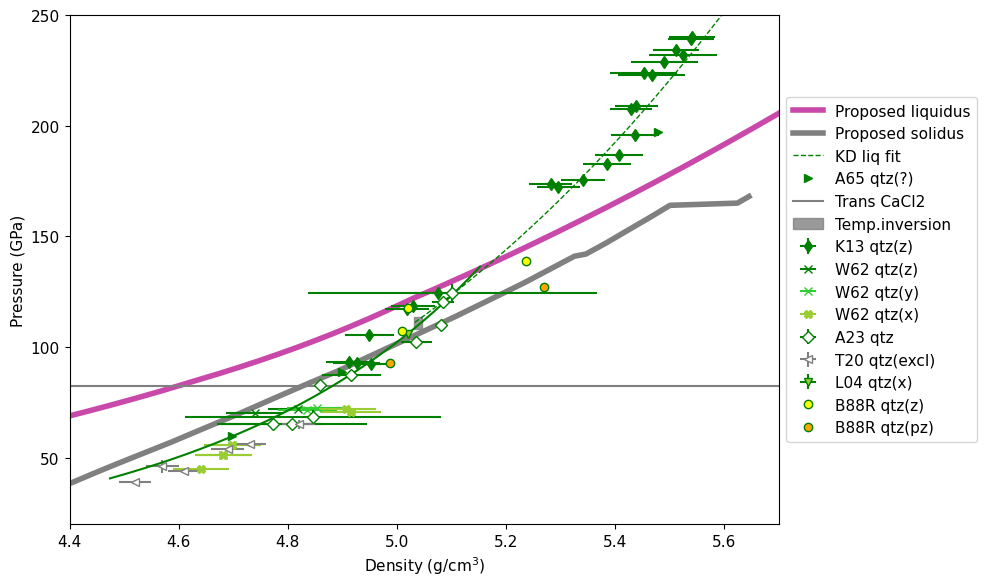

In [12]:
fig = plt.figure(figsize=(10, 6))
widthsol=4
# plot liquidus
ind = np.where(stsmcsmooth.rho < 5.65)[0]
ind = np.where(stsmcsmooth.rho > 0)[0]
plt.plot(stsmcsmooth.rho[ind],stsmcsmooth.P[ind],'-',color=mc_col,linewidth=widthsol,label='Proposed liquidus')
ind = np.where((stsmcsmooth.rho_s < 5.65) & (stsmcsmooth.rho_s > 0))[0]
plt.plot(stsmcsmooth.rho_s[ind],stsmcsmooth.P[ind],'-',color=sol_col,linewidth=widthsol,label='Proposed solidus')

plt.errorbar(shockdat_list[K13qtz['id']].rho,shockdat_list[K13qtz['id']].P,fmt='gd',markersize=6,\
             xerr=shockdat_list[K13qtz['id']].rho_std,yerr=shockdat_list[K13qtz['id']].P_std,label=K13qtz['lab']+'(z)')

#indhigh = np.where(fsdf['P'][indfs] > 74)[0]

#plt.errorbar(shockdat_list[W62qtz['id']].rho,shockdat_list[W62qtz['id']].P,fmt='gx',label=W62qtz['lab'])
#plt.errorbar(shockdat_list[W62fs['id']].rho,shockdat_list[W62fs['id']].P,fmt='bx',label=W62fs['lab'])
#plt.errorbar(shockdat_list[L83fshug['id']].rho,shockdat_list[L83fshug['id']].P,fmt='bo',label=L83fshug['lab'])

#plt.errorbar(fsdf['rho'][indfs],fsdf['P'][indfs],fmt='b+',label='M80 FS')
#plt.errorbar(qtzdf['rho'][indqtz],qtzdf['P'][indqtz],fmt='+',color='grey',label='Rusbank qtz excluded')
#indhigh = np.where((qtzdf['P'][indqtz] > 74) & (qtzdf['P'][indqtz] < 100))[0]
#print(indhigh)
#plt.errorbar(qtzdf['rho'][indqtz][indhigh],qtzdf['P'][indqtz][indhigh],fmt='g+',label='M80 qtz')
#mqtzup = deepcopy(np.asarray(qtzdf['up'][indqtz]))
#mqtzus = deepcopy(np.asarray(qtzdf['us'][indqtz]))
#mqtzrho = deepcopy(np.asarray(qtzdf['rho'][indqtz]))
#mqtzP = deepcopy(np.asarray(qtzdf['P'][indqtz]))
#inda = np.where((mqtzus>8) & (mqtzus<9.23))[0]
#plt.errorbar(mqtzrho[inda],mqtzP[inda],fmt='g+',label='M80 qtz included')

#plt.errorbar(shockdat_list[L83qtzhug['id']].rho,shockdat_list[L83qtzhug['id']].P,fmt='o',color='grey',mfc='white',\
#             yerr=shockdat_list[L83qtzhug['id']].P_std,xerr=shockdat_list[L83qtzhug['id']].rho_std,label=L83qtzhug['lab']+'(mult)')

#plt.errorbar(shockdat_list[W62qtz['id']].rho,shockdat_list[W62qtz['id']].P,fmt='gx',label=W62qtz['lab'],\
#            xerr=shockdat_list[W62qtz['id']].rho_std,yerr=shockdat_list[W62qtz['id']].P_std)
ind = np.where(shockdat_list[W62qtz['id']].orientation==' z')[0]
plt.errorbar(shockdat_list[W62qtz['id']].rho[ind],shockdat_list[W62qtz['id']].P[ind],\
             xerr=shockdat_list[W62qtz['id']].rho_std[ind],fmt='gx',label=W62qtz['lab']+'(z)')
ind = np.where(shockdat_list[W62qtz['id']].orientation==' y')[0]
plt.errorbar(shockdat_list[W62qtz['id']].rho[ind],shockdat_list[W62qtz['id']].P[ind],\
             xerr=shockdat_list[W62qtz['id']].rho_std[ind],fmt='x',color='limegreen',label=W62qtz['lab']+'(y)')
ind = np.where(shockdat_list[W62qtz['id']].orientation==' x')[0]
plt.errorbar(shockdat_list[W62qtz['id']].rho[ind],shockdat_list[W62qtz['id']].P[ind],\
             xerr=shockdat_list[W62qtz['id']].rho_std[ind],fmt='X',color='yellowgreen',label=W62qtz['lab']+'(x)')

plt.errorbar(shockdat_list[A23qtz['id']].rho,shockdat_list[A23qtz['id']].P,fmt='gD',mfc='white',label=A23qtz['lab'],\
            xerr=shockdat_list[A23qtz['id']].rho_std,yerr=shockdat_list[A23qtz['id']].P_std)
plt.errorbar(shockdat_list[T20qtz['id']].rho,shockdat_list[T20qtz['id']].P,fmt='<',mfc='white',color='grey',\
             xerr = shockdat_list[T20qtz['id']].rho_std, yerr=shockdat_list[T20qtz['id']].P_std, label=T20qtz['lab']+'(excl)')
#print(shockdat_list[T20qtz['id']].up,shockdat_list[T20qtz['id']].us)
#res = np.polyfit(shockdat_list[T20qtz['id']].up,shockdat_list[T20qtz['id']].us,1)
#print(res)
plt.errorbar(shockdat_list[L04qtz['id']].rho,shockdat_list[L04qtz['id']].P,fmt='gv',mfc='yellowgreen',\
         xerr=shockdat_list[L04qtz['id']].rho_std,yerr=shockdat_list[L04qtz['id']].P_std,label=L04qtz['lab']+'(x)')
#plt.errorbar(shockdat_list[B88RRqtz['id']].rho,shockdat_list[B88RRqtz['id']].P,fmt='go',mfc='red',\
#             yerr=shockdat_list[B88RRqtz['id']].P_std,label=B88RRqtz['lab'])
ind = np.where(np.asarray(shockdat_list[B88RRqtz['id']].orientation) == 'z')[0]
plt.errorbar(shockdat_list[B88RRqtz['id']].rho[ind],shockdat_list[B88RRqtz['id']].P[ind],fmt='go',mfc='yellow',\
             label=B88RRqtz['lab']+'(z)')
ind = np.where(np.asarray(shockdat_list[B88RRqtz['id']].orientation) == 'pz')[0]
plt.errorbar(shockdat_list[B88RRqtz['id']].rho[ind],shockdat_list[B88RRqtz['id']].P[ind],fmt='go',mfc='orange',\
             label=B88RRqtz['lab']+'(pz)')

ind = np.where(qtz_hug_liq.P>111)[0]
#ind = np.where(qtz_hug_liq.P>qtz_p_startliq)[0]
plt.plot(qtz_hug_liq.rho[ind],qtz_hug_liq.P[ind],'g--',linewidth=1,label='KD liq fit')
#ind2 = np.where((qtz_hug_glass.us > qtz_wiggle_us2) & (qtz_hug_glass.us <qtz_startliq_us))[0]
#plt.plot(qtz_hug_glass.rho[ind2],qtz_hug_glass.P[ind2],'-',color='springgreen',linewidth=3,label='Metastable region')


# Altshuler
palt = 2.65*np.asarray([3.13,3.92,6.2])*np.asarray([7.18,8.54,12.01])
#print('palt = ',palt)
rhoalt = 1./((1./2.65)*(1.-np.asarray([3.13,3.92,6.2])/np.asarray([7.18,8.54,12.01])))
plt.plot(rhoalt,palt,'g>',label='A65 qtz(?)')

# Fit CaCl2 region on the qtz Hugoniot

#plt.plot([0,10],[116.,116])
#print(shockdat_list[W62fs['id']].P)
#print(shockdat_list[L83fshug['id']].P)

#tmp = np.where(fitqtzcparr < 120)[0]
#plt.plot(fitqtzcrarr[tmp],fitqtzcparr[tmp],'g--',linewidth=3,label=r'Solid region fits')
#tmp = np.where(fitqtznparr < 68)[0]
#plt.plot(fitqtznrarr[tmp],fitqtznparr[tmp],'g--')



# plot new qtz data points from UCD gas gun lab
# Shots 47,48,44
#plt.plot([4.945,5.03885,5.078762118],[84.709,102.44,109.866],'rP',label='New qtz(z)') # MG release
#plt.plot([4.917,5.008],[84.153,101.7557],'rX',label='Shots 47,48 FLHUG')
#plt.plot([shot33.rho,shot26.rho,shot47.rho,shot48.rho,shot44.rho,shot45.rho],[shot33.P,shot26.P,shot47.P,shot48.P,shot44.P,shot45.P],'rP',label='New qtz(z)') # MG release

#plt.errorbar([shot33.rho],[shot33.P],xerr=[.0244*2],yerr=[0.476],label='New qtz(z)') # MG release

# shot 33
#plt.plot(shot33.rho,shot33.P,'rD',label='Shot 33')
# shot 26
#plt.plot(shot26.rho,shot26.P,'cD',label='Shot 26')
   

#plt.plot([4,8],[35,35],color='orange',label='FS trans to stv')
#plt.plot([4,5.5],[66,66],color='grey',label='Omega wiggle FS')
#plt.plot([4,5.5],[71,71],'--',color='grey')
#plt.plot([4,5.5],[79.4,79.4],color='grey')
plt.plot([0,20],[qtz_trans_cacl2_P,qtz_trans_cacl2_P],color='grey',label='Trans CaCl2') # stv enters melt curve

plt.fill_between([qtz_wiggle_rho1,qtz_wiggle_rho2],[qtz_wiggle_P1,qtz_wiggle_P1],[qtz_wiggle_P2,qtz_wiggle_P2],color='grey',alpha=0.8,label='Temp.inversion')
                
#plt.plot([4.,8],[108,108],color='tan',label='Omega wiggle qtz')
#plt.plot([4.,8],[112,112],color='tan')
#plt.plot([4.,58],[liqpmin,liqpmin],color='red',label='Qtz enters liquid')

#plt.plot(qtz_hug_sft.rho,qtz_hug_sft.P,'r-',linewidth=2,label='sft region fit')

#plt.plot([4,5],[80,80],color='red',label='sound speed melting')
plt.ylim(20,250)
plt.xlim(4.4,5.7)
#plt.ylim(20,500)
#plt.xlim(4.2,6.5)

#plt.plot(qtz_hug_stv.rho,qtz_hug_stv.P,'g-')
#plt.plot(qtz_hug_cacl2.rho,qtz_hug_cacl2.P,'g:')
plt.plot(qtz_hug_solid.rho,qtz_hug_solid.P,'g-')


plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))

plt.xlabel(r'Density (g/cm$^3$)')
plt.ylabel('Pressure (GPa)')
#plt.title('Qtz Hugoniot')

figname='H6-qtz-rho-P'
plt.tight_layout()
plt.savefig(outputfigpath+figname+'.pdf')
plt.show()
qtz_wiggle_us1 = 9.29 # km/s
qtz_wiggle_us2 = 9.5 # km/s
qtz_wiggle_P1 = np.interp(qtz_wiggle_us1,qtz_hug_cacl2.us,qtz_hug_cacl2.P)
qtz_wiggle_up1 = np.interp(qtz_wiggle_us1,qtz_hug_cacl2.us,qtz_hug_cacl2.up)
qtz_wiggle_rho1 = np.interp(qtz_wiggle_us1,qtz_hug_cacl2.us,qtz_hug_cacl2.rho)
qtz_wiggle_P2 = np.interp(qtz_wiggle_us2,qtz_hug_liq.us,qtz_hug_liq.P)
qtz_wiggle_up2 = np.interp(qtz_wiggle_us2,qtz_hug_liq.us,qtz_hug_liq.up)
qtz_wiggle_rho2 = np.interp(qtz_wiggle_us2,qtz_hug_liq.us,qtz_hug_liq.rho)


```{figure} ./figs/dot.png
---
width: 1px
name: qtz-P-rho
---
Hugoniot fits for $\alpha$-quartz. Note that different points are in different crystal orientations. There is indication of a multi-wave structure near 71-72 GPa (dashed line) corresponding to the stishovite to CaCl$_2$ transition on the Hugoniot. The thermal inversion feature is approximately 109 to 118 GPa. 

Note the B88R point at 127 GPa that is most compressed (5.27 g/cm$^3$) was cut perpendicular to the z-axis (pz). All data points in the seifertite region need to be re-analyzed with the phase transition to derive the correct density.

Perhaps coincidentally the data from {cite:t}`Tracy2020` fall on the fitted Hugoniot (left pointing triangles). These data were interpreted as the d-NiAs structure.

The steep sft region fit is empirical to attain 4800 K in the seifertite stability field in P-V space.
```

## Temperature Fits

RES b= [   173.75113152 -18503.2972858 ]
4000 K pressure =  113.4110155408729
RES a= [  168.39552949 -9390.03914284]
4000 K pressure =  62.82706956833862
figsize= [6.4, 4.8]
Saved figure: A3-SiO2-PTphase-diagram-with-qtz.pdf


<Figure size 1000x600 with 0 Axes>

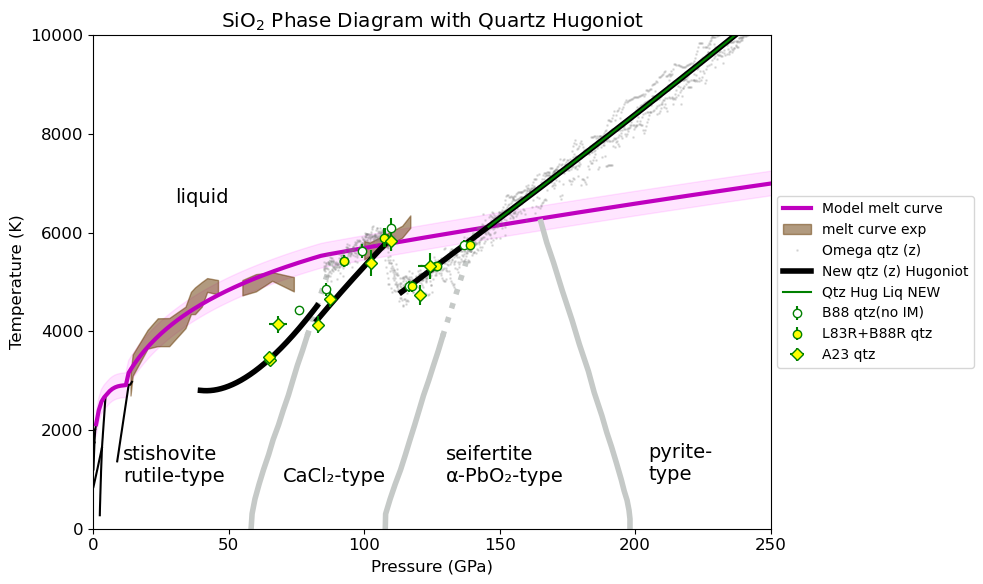

In [13]:
pind=4
%run -i scripts/PTphasediagram.py

CACL2 region T-Us Amodeo + 1 Boslough
inda= ['shot14' 'shot45' 'shot47' 'shot48']
indb= [1]
[8.46   9.317  9.032  8.2994]
[array([4661.      , 5837.      , 5384.      , 4136.765735]), array([5900.])]
[8.46   9.317  9.032  8.2994 9.27  ] [4661.       5837.       5384.       4136.765735 5900.      ]
HPEOS T-Us FIT CACL2 REGION
FIT EOS a =  [-9101.80418247  1609.02438713]
FIT EOS cov =  [[3685436.60074703 -421866.9456358 ]
 [-421866.9456358    48407.14364433]]
Saved EOS fit in qtz_fitTus_cacl2_linear.txt
Saved EOS fit in readable file qtz_fitTus_cacl2_linear-readable.txt
rms =  98.30804407168608
qtz_fitTus_cacl2 check:
Coefficients are the same.
[-9101.80418247  1609.02438713]
[-9101.80418247  1609.02438713]
STV region T-Us based on STV EOS and STV fitted Hugoniot
HPEOS T-Us FIT STV REGION
FIT EOS a =  [16752.43795921 -4574.27067987   374.82896128]
FIT EOS cov =  [[0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]]
Saved EOS fit in qtz_fitTus_stv_quadratic.txt
Saved EOS fit in readable file qtz_fitTus_st

/Users/sts/anaconda3/envs/silicapaper/lib/python3.13/site-packages/scipy/odr/_odrpack.py:394: RuntimeWarning: divide by zero encountered in divide
  return 1./np.power(sd, 2)


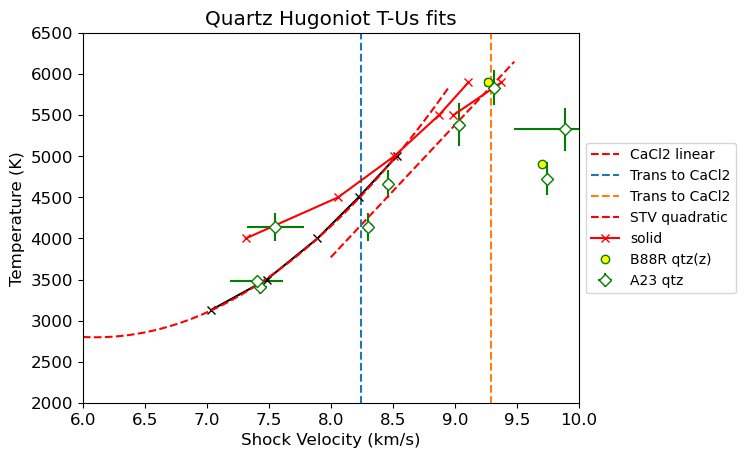

8.242930543631863


In [14]:


#plt.errorbar(shockdat_list[B88qtz['id']].us,shockdat_list[B88qtz['id']].T,fmt='go',mfc='white',yerr=shockdat_list[B88qtz['id']].T_std,label=B88qtz['lab']+'(mult cuts)')
#plt.errorbar(shockdat_list[S81qtz['id']].us,shockdat_list[S81qtz['id']].T,fmt='gx',label=S81qtz['lab']+'(unkwn)')

ind = np.where(shockdat_list[B88RRqtz['id']].orientation == 'z')[0]
plt.errorbar(shockdat_list[B88RRqtz['id']].us[ind],shockdat_list[B88RRqtz['id']].T[ind],fmt='go',mfc='yellow',\
             label=B88RRqtz['lab']+'(z)')
#ind = np.where(shockdat_list[B88RRqtz['id']].orientation == 'pz')[0]
#plt.errorbar(shockdat_list[B88RRqtz['id']].us[ind],shockdat_list[B88RRqtz['id']].T[ind],fmt='go',mfc='orange',\
#             label=B88RRqtz['lab']+'(pz)')
plt.errorbar(shockdat_list[A23qtz['id']].us,shockdat_list[A23qtz['id']].T,fmt='gD',mfc='white',label=A23qtz['lab'],\
            xerr=shockdat_list[A23qtz['id']].us_std,yerr=shockdat_list[A23qtz['id']].T_std)


#plt.plot(qtz_hug_cacl2.P,qtz_hug_cacl2.T,'g--',label='CaCl2 branch Hugoniot fit')

#plt.plot(qtz_hug_liq.P,qtz_hug_liq.T,'r-',label='Liquid branch Hugoniot (Z data fit)')



if 1:
    print('CACL2 region T-Us Amodeo + 1 Boslough')
    inda = np.where((shockdat_list[A23qtz['id']].us>8.2) & (shockdat_list[A23qtz['id']].us<9.4) & (shockdat_list[A23qtz['id']].exp_id != 'shot44') & (shockdat_list[A23qtz['id']].exp_id != 'shot28'))[0]
    print('inda=',shockdat_list[A23qtz['id']].exp_id[inda])
    indb = np.where((shockdat_list[B88RRqtz['id']].us>8.2) & (shockdat_list[B88RRqtz['id']].us<9.4) & (shockdat_list[B88RRqtz['id']].orientation == 'z'))[0]
    print('indb=',indb)

    fitupstv1 = [np.asarray(shockdat_list[A23qtz['id']].us)[inda],shockdat_list[B88RRqtz['id']].us[indb]]
    fitupstv = np.concatenate([np.atleast_1d(x) for x in fitupstv1])
    fituperrstv1 = [np.asarray(shockdat_list[A23qtz['id']].us_std)[inda],shockdat_list[B88RRqtz['id']].us_std[indb]]
    fituperrstv = np.concatenate([np.atleast_1d(x) for x in fituperrstv1])

    fitusstv1 = [np.asarray(shockdat_list[A23qtz['id']].T)[inda],shockdat_list[B88RRqtz['id']].T[indb]]
    fitusstv = np.concatenate([np.atleast_1d(x) for x in fitusstv1])
    fituserrstv1 = [np.asarray(shockdat_list[A23qtz['id']].T_std)[inda],shockdat_list[B88RRqtz['id']].T_std[indb]]
    fituserrstv = np.concatenate([np.atleast_1d(x) for x in fituserrstv1])

    r1 = np.full(len(inda), shockdat_list[A23qtz['id']].refidlist[1], dtype=int)
    r2 = np.full(1, shockdat_list[B88RRqtz['id']].refidlist[1], dtype=int)
    fitqtzrefid2 = np.concatenate((r1,r2))
    fitqtzreflist2=[]
    for i in np.unique(fitqtzrefid2):
        fitqtzreflist2.append(str(i)+': '+ref_list[i].reference[0])

    print(shockdat_list[A23qtz['id']].us[inda])
    print(fitusstv1)
    plt.plot(fitupstv,fitusstv,'rX')
    print(fitupstv,fitusstv)
    print('HPEOS T-Us FIT CACL2 REGION')
    # initialize the HPeos_Fit class
    qtz_fitTus_cacl2 = hp.HPeos_Fit()
    qtz_fitTus_cacl2.matid = 174
    qtz_fitTus_cacl2.material = 'Quartz'
    qtz_fitTus_cacl2.formula = 'SiO2'
    qtz_fitTus_cacl2.rho_ref = 2.650
    qtz_fitTus_cacl2.rho_ref_units = 'g/cm³'
    qtz_fitTus_cacl2.x = fitupstv
    qtz_fitTus_cacl2.f = fitusstv
    qtz_fitTus_cacl2.x_std = fituperrstv
    qtz_fitTus_cacl2.f_std = fituserrstv
    qtz_fitTus_cacl2.refid = fitqtzrefid2
    qtz_fitTus_cacl2.reflist = fitqtzreflist2
    qtz_fitTus_cacl2.x_var = 'us'
    qtz_fitTus_cacl2.f_var = 'T'
    qtz_fitTus_cacl2.x_units = 'km/s'
    qtz_fitTus_cacl2.f_units = 'K'
    qtz_fitTus_cacl2.x_desc = 'Shock Velocity'
    qtz_fitTus_cacl2.f_desc = 'Temperature'
    qtz_fitTus_cacl2.phase_fit = 'CaCl2'
    qtz_fitTus_cacl2.remlist.append('Fit to CaCl2-type region on the Hugoniot.')
    DateTime_in_ISOFormat = datetime.datetime.now(zoneinfo.ZoneInfo('UTC')).isoformat('T', 'seconds') #
    qtz_fitTus_cacl2.actions = [['Sarah T. Stewart','create',DateTime_in_ISOFormat,'new fit']]

    qtz_fitTus_cacl2.curvetype = 'linear'
    qtz_fitTus_cacl2.outputfitpath = outputfitpath # in load_paths.py
    qtz_fitTus_cacl2.filename = 'qtz_fitTus_cacl2_linear'
    qtz_fitTus_cacl2.fit()
    print('FIT EOS a = ',qtz_fitTus_cacl2.a)
    print('FIT EOS cov = ',qtz_fitTus_cacl2.cov)
    qtz_fitTus_cacl2.savejson()
    qtz_fitTus_cacl2.savereadable()
    print('rms = ',qtz_fitTus_cacl2.rms)

    print('qtz_fitTus_cacl2 check:')
    qtz_fitTus_cacl2.comparecoefs(qtz_fitTus_cacl20.a)

    nup = np.arange(8,9.5,.04)
    nus = qtz_fitTus_cacl2.calcf(nup)
    plt.plot(nup,nus,'r--',label='CaCl2 linear')

plt.plot([qtz_trans_cacl2_us,qtz_trans_cacl2_us],[0,10000],'--',label='Trans to CaCl2')
plt.plot([qtz_wiggle_us1,qtz_wiggle_us1],[0,10000],'--',label='Trans to CaCl2')


plt.plot(stvusmodel,stvtmodel,'k-x')
plt.plot(cacl2usmodel,cacl2tmodel,'r-x')


if 1:
    print('STV region T-Us based on STV EOS and STV fitted Hugoniot')

    fitupstv = stvusmodel
    fituperrstv = np.zeros(len(fitupstv))
    fitusstv = stvtmodel
    fituserrstv = np.zeros(len(fitupstv))

    fitqtzrefid2 = np.full(len(fitupstv), shockdat_list[A23qtz['id']].refidlist[1], dtype=int)
    fitqtzreflist2=[]
    for i in np.unique(fitqtzrefid2):
        fitqtzreflist2.append(str(i)+': '+ref_list[i].reference[0])

    print('HPEOS T-Us FIT STV REGION')
    # initialize the HPeos_Fit class
    qtz_fitTus_stv = hp.HPeos_Fit()
    qtz_fitTus_stv.matid = 174
    qtz_fitTus_stv.material = 'Quartz'
    qtz_fitTus_stv.formula = 'SiO2'
    qtz_fitTus_stv.rho_ref = 2.650
    qtz_fitTus_stv.rho_ref_units = 'g/cm³'
    qtz_fitTus_stv.x = fitupstv
    qtz_fitTus_stv.f = fitusstv
    qtz_fitTus_stv.x_std = fituperrstv
    qtz_fitTus_stv.f_std = fituserrstv
    qtz_fitTus_stv.refid = fitqtzrefid2
    qtz_fitTus_stv.reflist = fitqtzreflist2
    qtz_fitTus_stv.x_var = 'us'
    qtz_fitTus_stv.f_var = 'T'
    qtz_fitTus_stv.x_units = 'km/s'
    qtz_fitTus_stv.f_units = 'K'
    qtz_fitTus_stv.x_desc = 'Shock Velocity'
    qtz_fitTus_stv.f_desc = 'Temperature'
    qtz_fitTus_stv.phase_fit = 'stishovite'
    qtz_fitTus_stv.remlist.append('Fit to stishovite region on the Hugoniot.')
    qtz_fitTus_stv.remlist.append('Temperatures are based on STV EOS model using the fitted Us-up Hugoniot.')
    DateTime_in_ISOFormat = datetime.datetime.now(zoneinfo.ZoneInfo('UTC')).isoformat('T', 'seconds') #
    qtz_fitTus_stv.actions = [['Sarah T. Stewart','create',DateTime_in_ISOFormat,'new fit']]

    qtz_fitTus_stv.curvetype = 'quadratic'
    qtz_fitTus_stv.outputfitpath = outputfitpath # in load_paths.py
    qtz_fitTus_stv.filename = 'qtz_fitTus_stv_quadratic'
    qtz_fitTus_stv.fit()
    print('FIT EOS a = ',qtz_fitTus_stv.a)
    print('FIT EOS cov = ',qtz_fitTus_stv.cov)
    qtz_fitTus_stv.savejson()
    qtz_fitTus_stv.savereadable()
    print('rms = ',qtz_fitTus_stv.rms)

    print('qtz_fitTus_stv check:')
    qtz_fitTus_stv.comparecoefs(qtz_fitTus_stv0.a)

    nup = np.arange(6,9.,.04)
    nus = qtz_fitTus_stv.calcf(nup)
    plt.plot(nup,nus,'r--',label='STV quadratic')

plt.plot(solidusmodel,solidtmodel,'rx-',label='solid')
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5),fontsize=10)
plt.xlabel('Shock Velocity (km/s)')
plt.ylabel('Temperature (K)')
plt.ylim(2000,6500)
plt.xlim(6,10)
plt.title('Quartz Hugoniot T-Us fits')
plt.show()
print(qtz_trans_cacl2_us)


In [15]:
print(shockdat_list[B88RRqtz['id']].T)
print(shockdat_list[B88RRqtz['id']].P)
print(shockdat_list[B88RRqtz['id']].us)

indz = np.where(shockdat_list[B88RRqtz['id']].orientation == 'z')[0]
print(shockdat_list[B88RRqtz['id']].T[ind])
print(shockdat_list[B88RRqtz['id']].P[ind])
print(shockdat_list[B88RRqtz['id']].us[ind])


[5430. 5900. 4910. 5320. 5760. 4440. 4850. 5630. 6100.]
[ 92.64844931 107.25686863 117.77935509 126.98567629 138.87270554
  75.9         85.9         99.3        109.7       ]
[ 8.64  9.27  9.7   9.82 10.3   0.    0.    0.    0.  ]
[5900. 4910. 5760. 4850.]
[107.25686863 117.77935509 138.87270554  85.9       ]
[ 9.27  9.7  10.3   0.  ]


all solid region T-Us Amodeo; shot 27 mod
inda= ['shot14' 'shot45' 'shot47' 'shot48']
[107.25686863 117.77935509 138.87270554  85.9       ]
usb =  9.252666384714555
data:
[0 6 7 8] 1
[8.46       9.317      9.032      8.2994     7.42       9.25266638]
[0.015      0.0111     0.046      0.0042     0.012      0.46263332]
[4661.       5837.       5384.       4136.765735 3412.766828 5900.      ]
[172.       213.       264.       169.151493  91.982392 200.      ]
HPEOS T-Us FIT ALL SOLID REGION
FIT EOS a =  [13817.14362212 -3554.25351558   289.9608017 ]
FIT EOS cov =  [[ 1.56253617e+08 -3.81866164e+07  2.31515479e+06]
 [-3.81866164e+07  9.34151115e+06 -5.66912756e+05]
 [ 2.31515479e+06 -5.66912756e+05  3.44400177e+04]]
Saved EOS fit in qtz_fitTus_solid_quadratic.txt
Saved EOS fit in readable file qtz_fitTus_solid_quadratic-readable.txt
rms =  109.58871123287201
qtz_fitTus_solid check:
Coefficients are the same.
[13817.14362212 -3554.25351558   289.9608017 ]
[13817.14362212 -3554.25351558   28

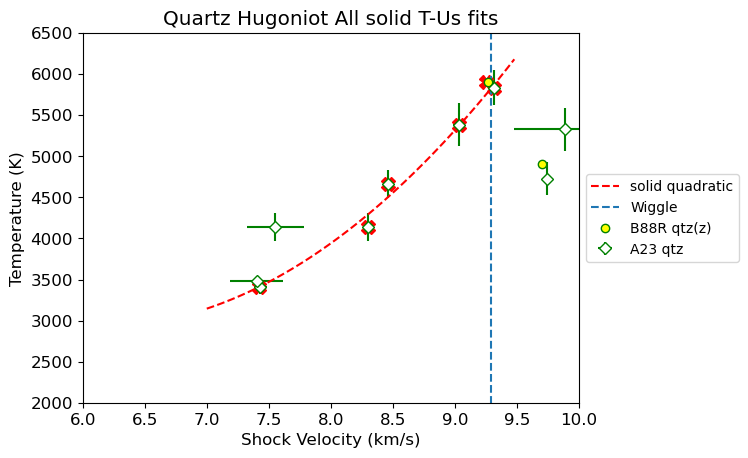

In [16]:
# Fit all solid region; Amodeo data + 1 Boslough only

#plt.errorbar(shockdat_list[B88qtz['id']].us,shockdat_list[B88qtz['id']].T,fmt='go',mfc='white',yerr=shockdat_list[B88qtz['id']].T_std,label=B88qtz['lab']+'(mult cuts)')
#plt.errorbar(shockdat_list[S81qtz['id']].us,shockdat_list[S81qtz['id']].T,fmt='gx',label=S81qtz['lab']+'(unkwn)')

ind = np.where(shockdat_list[B88RRqtz['id']].orientation == 'z')[0]
plt.errorbar(shockdat_list[B88RRqtz['id']].us[ind],shockdat_list[B88RRqtz['id']].T[ind],fmt='go',mfc='yellow',\
             label=B88RRqtz['lab']+'(z)')
#ind = np.where(shockdat_list[B88RRqtz['id']].orientation == 'pz')[0]
#plt.errorbar(shockdat_list[B88RRqtz['id']].us[ind],shockdat_list[B88RRqtz['id']].T[ind],fmt='go',mfc='orange',\
#             label=B88RRqtz['lab']+'(pz)')
plt.errorbar(shockdat_list[A23qtz['id']].us,shockdat_list[A23qtz['id']].T,fmt='gD',mfc='white',label=A23qtz['lab'],\
            xerr=shockdat_list[A23qtz['id']].us_std,yerr=shockdat_list[A23qtz['id']].T_std)


#plt.plot(qtz_hug_cacl2.P,qtz_hug_cacl2.T,'g--',label='CaCl2 branch Hugoniot fit')

#plt.plot(qtz_hug_liq.P,qtz_hug_liq.T,'r-',label='Liquid branch Hugoniot (Z data fit)')



if 0:
    print('all solid region T-Us Amodeo + 1 Boslough (P=85.9)')
    inda = np.where((shockdat_list[A23qtz['id']].us>8) & (shockdat_list[A23qtz['id']].us<9.4) & (shockdat_list[A23qtz['id']].exp_id != 'shot44') & (shockdat_list[A23qtz['id']].exp_id != 'shot28') & (shockdat_list[A23qtz['id']].exp_id != 'shot27'))[0]
    print('inda=',shockdat_list[A23qtz['id']].exp_id[inda])
    indb = np.where((shockdat_list[B88RRqtz['id']].us>7) & (shockdat_list[B88RRqtz['id']].us<9.4) & (shockdat_list[B88RRqtz['id']].orientation == 'z'))[0]
    print('indb=',indb)
    indz = np.where(shockdat_list[B88RRqtz['id']].orientation == 'z')[0]
    indb = indz[3] # no us known; use fitted EOS
    usb = np.interp(shockdat_list[B88RRqtz['id']].P[indb],qtz_hug_solid.P,qtz_hug_solid.us)
    usb_std = usb*.05
    print('usb = ',usb)

    inda27 = np.where(shockdat_list[A23qtz['id']].exp_id == 'shot27')[0]
    

    fitx1 = [np.asarray(shockdat_list[A23qtz['id']].us)[inda],usb,[7.42]]
    fitx = np.concatenate([np.atleast_1d(x) for x in fitx1])
    fitx_std1 = [np.asarray(shockdat_list[A23qtz['id']].us_std)[inda],usb_std,[.012]]
    fitx_std = np.concatenate([np.atleast_1d(x) for x in fitx_std1])

    fity1 = [np.asarray(shockdat_list[A23qtz['id']].T)[inda],shockdat_list[B88RRqtz['id']].T[indb],np.asarray(shockdat_list[A23qtz['id']].T)[inda27]]
    fity = np.concatenate([np.atleast_1d(x) for x in fity1])
    fity_std1 = [np.asarray(shockdat_list[A23qtz['id']].T_std)[inda],shockdat_list[B88RRqtz['id']].T_std[indb],np.asarray(shockdat_list[A23qtz['id']].T_std)[inda27]]
    fity_std = np.concatenate([np.atleast_1d(x) for x in fity_std1])

    r1 = np.full(len(inda), shockdat_list[A23qtz['id']].refidlist[1], dtype=int)
    r2 = np.full(1, shockdat_list[B88RRqtz['id']].refidlist[1], dtype=int)
    r3 = np.full(len(inda), shockdat_list[A23qtz['id']].refidlist[1], dtype=int)
    fitqtzrefid2 = np.concatenate((r1,r2,r3))
    fitqtzreflist2=[]
    for i in np.unique(fitqtzrefid2):
        fitqtzreflist2.append(str(i)+': '+ref_list[i].reference[0])

#    print(shockdat_list[A23qtz['id']].us[inda])
    print('data:')
    print(inda,indb)
    print(fitx)
    print(fitx_std)
    print(fity)
    print(fity_std)


if 1:
    print('all solid region T-Us Amodeo; shot 27 mod')
    inda = np.where((shockdat_list[A23qtz['id']].us>8) & (shockdat_list[A23qtz['id']].us<9.4) & (shockdat_list[A23qtz['id']].exp_id != 'shot44') & (shockdat_list[A23qtz['id']].exp_id != 'shot28') & (shockdat_list[A23qtz['id']].exp_id != 'shot27'))[0]
    print('inda=',shockdat_list[A23qtz['id']].exp_id[inda])
    inda27 = np.where(shockdat_list[A23qtz['id']].exp_id == 'shot27')[0]
    indz = np.where(shockdat_list[B88RRqtz['id']].orientation == 'z')[0]
    print(shockdat_list[B88RRqtz['id']].P[indz])
    indb = indz[0] # no us known; use fitted EOS
    usb = np.interp(shockdat_list[B88RRqtz['id']].P[indb],qtz_hug_solid.P,qtz_hug_solid.us)
    usb_std = usb*.05
    print('usb = ',usb)

        
    fitx1 = [np.asarray(shockdat_list[A23qtz['id']].us)[inda],[7.42],usb]
    fitx = np.concatenate([np.atleast_1d(x) for x in fitx1])
    fitx_std1 = [np.asarray(shockdat_list[A23qtz['id']].us_std)[inda],[.012],usb_std]
    fitx_std = np.concatenate([np.atleast_1d(x) for x in fitx_std1])

    fity1 = [np.asarray(shockdat_list[A23qtz['id']].T)[inda],np.asarray(shockdat_list[A23qtz['id']].T)[inda27],shockdat_list[B88RRqtz['id']].T[indb]]
    fity = np.concatenate([np.atleast_1d(x) for x in fity1])
    fity_std1 = [np.asarray(shockdat_list[A23qtz['id']].T_std)[inda],np.asarray(shockdat_list[A23qtz['id']].T_std)[inda27],shockdat_list[B88RRqtz['id']].T_std[indb]]
    fity_std = np.concatenate([np.atleast_1d(x) for x in fity_std1])


    r1 = np.full(len(inda), shockdat_list[A23qtz['id']].refidlist[1], dtype=int)
    r3 = np.full(len(inda), shockdat_list[A23qtz['id']].refidlist[1], dtype=int)
    r4 = np.full(1, shockdat_list[B88RRqtz['id']].refidlist[1], dtype=int)
    fitqtzrefid2 = np.concatenate((r1,r3,r4))
    fitqtzreflist2=[]
    for i in np.unique(fitqtzrefid2):
        fitqtzreflist2.append(str(i)+': '+ref_list[i].reference[0])

#    print(shockdat_list[A23qtz['id']].us[inda])
    print('data:')
    print(inda,indb)
    print(fitx)
    print(fitx_std)
    print(fity)
    print(fity_std)

    plt.plot(fitx,fity,'rX',markersize=10)
    print('HPEOS T-Us FIT ALL SOLID REGION')
    # initialize the HPeos_Fit class
    qtz_fitTus_solid = hp.HPeos_Fit()
    qtz_fitTus_solid.matid = 174
    qtz_fitTus_solid.material = 'Quartz'
    qtz_fitTus_solid.formula = 'SiO2'
    qtz_fitTus_solid.rho_ref = 2.650
    qtz_fitTus_solid.rho_ref_units = 'g/cm³'
    qtz_fitTus_solid.x = fitx
    qtz_fitTus_solid.f = fity
    qtz_fitTus_solid.x_std = fitx_std
    qtz_fitTus_solid.f_std = fity_std
    qtz_fitTus_solid.refid = fitqtzrefid2
    qtz_fitTus_solid.reflist = fitqtzreflist2
    qtz_fitTus_solid.x_var = 'us'
    qtz_fitTus_solid.f_var = 'T'
    qtz_fitTus_solid.x_units = 'km/s'
    qtz_fitTus_solid.f_units = 'K'
    qtz_fitTus_solid.x_desc = 'Shock Velocity'
    qtz_fitTus_solid.f_desc = 'Temperature'
    qtz_fitTus_solid.phase_fit = 'solid'
    qtz_fitTus_solid.remlist.append('Fit to T-Us for all region on the Hugoniot: Amodeo and Boslough data with impedance match only.')
    DateTime_in_ISOFormat = datetime.datetime.now(zoneinfo.ZoneInfo('UTC')).isoformat('T', 'seconds') #
    qtz_fitTus_solid.actions = [['Sarah T. Stewart','create',DateTime_in_ISOFormat,'new fit']]

    qtz_fitTus_solid.curvetype = 'quadratic'
    qtz_fitTus_solid.outputfitpath = outputfitpath # in load_paths.py
    qtz_fitTus_solid.filename = 'qtz_fitTus_solid_quadratic'
    qtz_fitTus_solid.fit()
    print('FIT EOS a = ',qtz_fitTus_solid.a)
    print('FIT EOS cov = ',qtz_fitTus_solid.cov)
    qtz_fitTus_solid.savejson()
    qtz_fitTus_solid.savereadable()
    print('rms = ',qtz_fitTus_solid.rms)

    print('qtz_fitTus_solid check:')
    qtz_fitTus_solid.comparecoefs(qtz_fitTus_solid0.a)

    nup = np.arange(7,9.5,.04)
    nus = qtz_fitTus_solid.calcf(nup)
    plt.plot(nup,nus,'r--',label='solid quadratic')

#plt.plot([qtz_trans_cacl2_us,qtz_trans_cacl2_us],[0,10000],'--',label='Trans to CaCl2')
plt.plot([qtz_wiggle_us1,qtz_wiggle_us1],[0,10000],'--',label='Wiggle')


#plt.plot(stvusmodel,stvtmodel,'k-x')
#plt.plot(cacl2usmodel,cacl2tmodel,'r-x')


plt.legend(loc='center left', bbox_to_anchor=(1, 0.5),fontsize=10)
plt.xlabel('Shock Velocity (km/s)')
plt.ylabel('Temperature (K)')
plt.ylim(2000,6500)
plt.xlim(6,10)
plt.title('Quartz Hugoniot All solid T-Us fits')
plt.show()
#print(qtz_trans_cacl2_us)


In [17]:
print('CHECK THIS Quartz SOLID region Solidus intersection:')
x,y=intersection(stsmcsmooth.P,stsmcsmooth.rho_s,qtz_hug_solid.P,qtz_hug_solid.rho)
print('P, rho intersection point = ',x,y)
print('us = ',np.interp(x,qtz_hug_solid.P,qtz_hug_solid.us))
print('up = ',np.interp(x,qtz_hug_solid.P,qtz_hug_solid.up))
print('T = ',np.interp(x,qtz_hug_solid.P,qtz_hug_solid.T))

print('Compare to P, us = ',qtz_startsol_P,qtz_startsol_us)

CHECK THIS Quartz SOLID region Solidus intersection:
P, rho intersection point =  [100.50773756] [4.99116474]
us =  [8.9921134]
up =  [4.21785694]
T =  [5302.57353325]
Compare to P, us =  100.50773755669458 8.992113395140894


16.42
13.23
13.22
18.6
Temperature fit in the liquid region: 
(array([ 7.17555125e+00, -1.61423024e+02,  2.36687007e+03, -9.37407549e+03]), array([[ 9.45671473e-02, -3.90306920e+00,  5.25826556e+01,
        -2.31165369e+02],
       [-3.90306920e+00,  1.61629916e+02, -2.18489073e+03,
         9.63724761e+03],
       [ 5.25826556e+01, -2.18489073e+03,  2.96392333e+04,
        -1.31196661e+05],
       [-2.31165369e+02,  9.63724761e+03, -1.31196661e+05,
         5.82849629e+05]]))
HPEOS T-Us FIT LIQUID REGION
FIT EOS a =  [-4391.27584577  1263.49808289   -81.26334251     5.26247505]
FIT EOS cov =  [[ 8.27233932e+06 -1.91911572e+06  1.45809520e+05 -3.62473982e+03]
 [-1.91911572e+06  4.46699097e+05 -3.40511149e+04  8.49217008e+02]
 [ 1.45809520e+05 -3.40511149e+04  2.60436381e+03 -6.51689028e+01]
 [-3.62473982e+03  8.49217008e+02 -6.51689028e+01  1.63632442e+00]]
Saved EOS fit in qtz_fitTus_liq_cubic.txt
Saved EOS fit in readable file qtz_fitTus_liq_cubic-readable.txt
rms =  197.938452416862

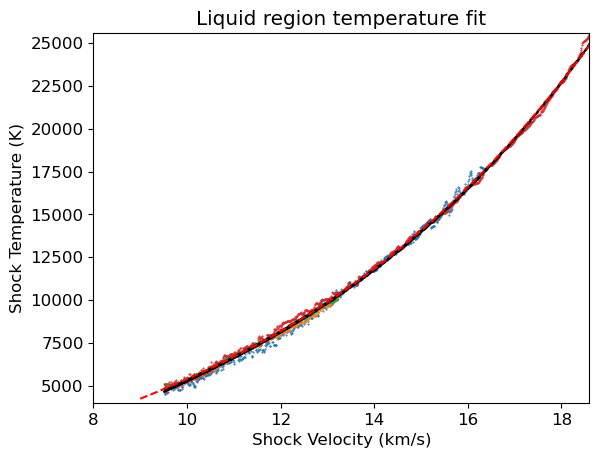

In [18]:
# Fit the Omega data above Us 10.5 km/s for liquid region

mss = 1

print(max(M70811.us))
print(max(M70813.us))
print(max(M70817.us))
print(max(M70820.us))


# FIT the Seifertite region 9.5 to 10.4 km/s
qtz_us_fitmax = 35
us_fitstart=qtz_wiggle_us2
ind11 = np.where((M70811.us > us_fitstart) & (M70811.us < qtz_us_fitmax) )[0]
ind13 = np.where((M70813.us > us_fitstart) & (M70813.us < qtz_us_fitmax) )[0]
ind17 = np.where((M70817.us > us_fitstart) & (M70817.us < qtz_us_fitmax) )[0]
ind20 = np.where((M70820.us > us_fitstart) & (M70820.us < qtz_us_fitmax) )[0]

plt.plot(M70811.us[ind11],M70811.T[ind11],'.',markersize=mss)
plt.plot(M70813.us[ind13],M70813.T[ind13],'.',markersize=mss)
plt.plot(M70817.us[ind17],M70817.T[ind17],'.',markersize=mss)
plt.plot(M70820.us[ind20],M70820.T[ind20],'.',markersize=mss)


fitus = np.concatenate((M70811.us[ind11],M70813.us[ind13],M70817.us[ind17],M70820.us[ind20]))
fitt = np.concatenate((M70811.T[ind11],M70813.T[ind13],M70817.T[ind17],M70820.T[ind20]))

rescov = np.polyfit(fitus,fitt,3,cov=True)
print('Temperature fit in the liquid region: ')
print(rescov)
res=rescov[0]
plt.plot(fitus,res[3]+res[2]*fitus+res[1]*fitus**2+res[0]*fitus**3,'k.',linewidth=3,markersize=mss)

#plt.plot(qtz_hug_liq.us,qtz_hug_liq.T,'g-',label='Qtz Hug Liq NEW')

if 1:
    fitus_std = .005*fitus
    fitt_std = np.concatenate((M70811.T_std[ind11],M70813.T_std[ind13],M70817.T_std[ind17],M70820.T_std[ind20]))
    
    r1 = np.full(len(fitus), shockdat_list[MDqtz70811['id']].refidlist[1], dtype=int)
   # fitqtzrefid2 = np.concatenate((r1))
    fitqtzreflist2=[]
    for i in np.unique(r1):
        fitqtzreflist2.append(str(i)+': '+ref_list[i].reference[0])

    print('HPEOS T-Us FIT LIQUID REGION')
    # initialize the HPeos_Fit class
    qtz_fitTus_liq = hp.HPeos_Fit()
    qtz_fitTus_liq.matid = 174
    qtz_fitTus_liq.material = 'Quartz'
    qtz_fitTus_liq.formula = 'SiO2'
    qtz_fitTus_liq.rho_ref = 2.650
    qtz_fitTus_liq.rho_ref_units = 'g/cm³'
    qtz_fitTus_liq.x = fitus
    qtz_fitTus_liq.f = fitt
    qtz_fitTus_liq.x_std = fitus_std
    qtz_fitTus_liq.f_std = fitt_std
    qtz_fitTus_liq.refid = r1
    qtz_fitTus_liq.reflist = fitqtzreflist2
    qtz_fitTus_liq.x_var = 'us'
    qtz_fitTus_liq.f_var = 'T'
    qtz_fitTus_liq.x_units = 'km/s'
    qtz_fitTus_liq.f_units = 'K'
    qtz_fitTus_liq.x_desc = 'Shock Velocity'
    qtz_fitTus_liq.f_desc = 'Temperature'
    qtz_fitTus_liq.phase_fit = 'liquid'
    qtz_fitTus_liq.remlist.append('Fit to liquid region on the Hugoniot including supercooled shock front below the melt curve.')
    qtz_fitTus_liq.remlist.append('Only including Omega decaying shock data.')
    DateTime_in_ISOFormat = datetime.datetime.now(zoneinfo.ZoneInfo('UTC')).isoformat('T', 'seconds') #
    qtz_fitTus_liq.actions = [['Sarah T. Stewart','create',DateTime_in_ISOFormat,'new fit']]

    qtz_fitTus_liq.curvetype = 'cubic'
    qtz_fitTus_liq.outputfitpath = outputfitpath # in load_paths.py
    qtz_fitTus_liq.filename = 'qtz_fitTus_liq_cubic'
    qtz_fitTus_liq.fit()
    print('FIT EOS a = ',qtz_fitTus_liq.a)
    print('FIT EOS cov = ',qtz_fitTus_liq.cov)
    qtz_fitTus_liq.savejson()
    qtz_fitTus_liq.savereadable()
    print('rms = ',qtz_fitTus_liq.rms)

    print('qtz_fitTus_liq check:')
    qtz_fitTus_liq.comparecoefs(qtz_fitTus_liq0.a)

    nup = np.arange(9,20,.04)
    nus = qtz_fitTus_liq.calcf(nup)
    plt.plot(nup,nus,'r--',label='fit cubic')




plt.xlim(8,max(fitus))
plt.ylim(4000,max(fitt))
plt.ylabel('Shock Temperature (K)')
plt.xlabel('Shock Velocity (km/s)')
#plt.plot([qtz_startliq_us ,qtz_startliq_us ],[0,10000],'k-')
#plt.plot([0,20],[6212,6212],'k-')
plt.title('Liquid region temperature fit')
plt.savefig(outputfigpath+'H1c-Omega-qtz-Us-T.pdf')
plt.show()



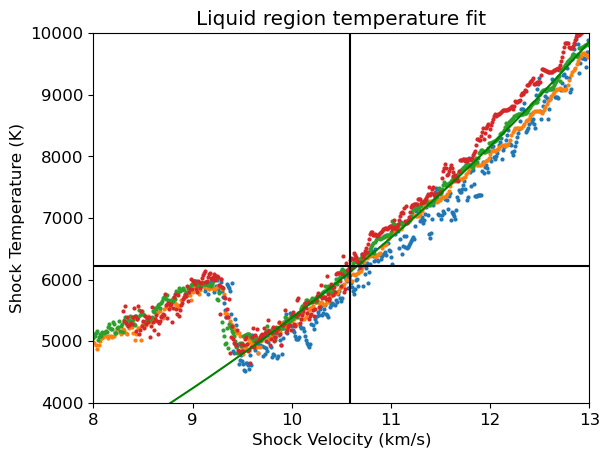

In [19]:
# Fit the Omega data above Us 10.5 km/s for liquid region

mss = 4
plt.plot(M70811.us,M70811.T,'.',markersize=mss)
plt.plot(M70813.us,M70813.T,'.',markersize=mss)
plt.plot(M70817.us,M70817.T,'.',markersize=mss)
plt.plot(M70820.us,M70820.T,'.',markersize=mss)

if 0:
    qtz_us_fitmax = 15
    us_fitstart=qtz_wiggle_us2
    ind11 = np.where((M70811.us > us_fitstart) & (M70811.us < qtz_us_fitmax) )[0]
    ind13 = np.where((M70813.us > us_fitstart) & (M70813.us < qtz_us_fitmax) )[0]
    ind17 = np.where((M70817.us > us_fitstart) & (M70817.us < qtz_us_fitmax) )[0]
    ind20 = np.where((M70820.us > us_fitstart) & (M70820.us < qtz_us_fitmax) )[0]
    fitus = np.concatenate((M70811.us[ind11],M70813.us[ind13],M70817.us[ind17],M70820.us[ind20]))
    fitt = np.concatenate((M70811.T[ind11],M70813.T[ind13],M70817.T[ind17],M70820.T[ind20]))
    
    rescov = np.polyfit(fitus,fitt,3,cov=True)
    print('Temperature fit in the liquid region: ')
    print(rescov)
    res=rescov[0]
    plt.plot(fitus,res[3]+res[2]*fitus+res[1]*fitus**2+res[0]*fitus**3,'k.',linewidth=1,markersize=mss)

plt.plot(qtz_hug_liq.us,qtz_hug_liq.T,'g-',label='Qtz Hug Liq NEW')


plt.xlim(8,13)
plt.ylim(4000,10000)
plt.ylabel('Shock Temperature (K)')
plt.xlabel('Shock Velocity (km/s)')
plt.plot([qtz_startliq_us ,qtz_startliq_us ],[0,10000],'k-')
plt.plot([0,20],[6212,6212],'k-')
plt.title('Liquid region temperature fit')
plt.savefig(outputfigpath+'H1c-Omega-qtz-Us-T.pdf')
plt.show()


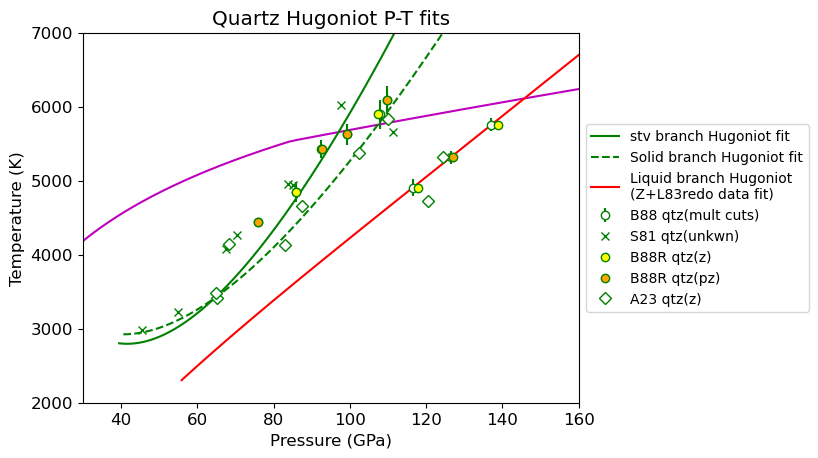

In [20]:

plt.plot(stsmcsmooth.P,stsmcsmooth.T,'m-')
plt.errorbar(shockdat_list[B88qtz['id']].P,shockdat_list[B88qtz['id']].T,fmt='go',mfc='white',yerr=shockdat_list[B88qtz['id']].T_std,label=B88qtz['lab']+'(mult cuts)')
plt.errorbar(shockdat_list[S81qtz['id']].P,shockdat_list[S81qtz['id']].T,fmt='gx',label=S81qtz['lab']+'(unkwn)')

ind = np.where(shockdat_list[B88RRqtz['id']].orientation == 'z')[0]
plt.errorbar(shockdat_list[B88RRqtz['id']].P[ind],shockdat_list[B88RRqtz['id']].T[ind],fmt='go',mfc='yellow',\
             label=B88RRqtz['lab']+'(z)')
ind = np.where(shockdat_list[B88RRqtz['id']].orientation == 'pz')[0]
plt.errorbar(shockdat_list[B88RRqtz['id']].P[ind],shockdat_list[B88RRqtz['id']].T[ind],fmt='go',mfc='orange',\
             label=B88RRqtz['lab']+'(pz)')
plt.errorbar(shockdat_list[A23qtz['id']].P,shockdat_list[A23qtz['id']].T,fmt='gD',mfc='white',\
             label=A23qtz['lab']+'(z)')

if 0:
    # old UCD fit
    # new high-precision data (upper 3 points; lowest has T but poor Us so using P from the fit)
    ucdpnew = np.asarray([65.29,84.709,102.44,109.866])
    ucdtnew = np.asarray([3576.6,4484,5384,5837])
    ucdtnew_err = np.asarray([57,212,264,213])
    plt.errorbar(ucdpnew,ucdtnew,yerr=ucdtnew_err,fmt='gD',mfc='white',label='New qtz(z-cut)')
    
    
    inda= np.where(shockdat_list[B88qtz['id']].P < 111)
    #print(shockdat_list[B88qtz['id']].P[inda])
    indb= np.where((shockdat_list[S81qtz['id']].P < 111) & (shockdat_list[S81qtz['id']].P >60))
    #print(shockdat_list[S81qtz['id']].P[indb])
    
    #fitp = np.concatenate((shockdat_list[B88qtz['id']].P[inda],shockdat_list[S81qtz['id']].P[indb]))
    #fitt = np.concatenate((shockdat_list[B88qtz['id']].T[inda],shockdat_list[S81qtz['id']].T[indb]))
    #res = np.polyfit(fitp,fitt,1,cov=True)
    
    
    rescov = np.polyfit(ucdpnew,ucdtnew,1,cov=True)
    res = rescov[0]
    print('UCD FIT CaCl2-branch P-T fit for z-cut qtz =')
    print(rescov)
    ptemp = np.arange(40,Pt3)
    plt.plot(ptemp,res[1]+res[0]*ptemp)

#if 1:
    # new UCD fit summer 2024
    



plt.plot(qtz_hug_stv.P,qtz_hug_stv.T,'g-',label='stv branch Hugoniot fit')
plt.plot(qtz_hug_solid.P,qtz_hug_solid.T,'g--',label='Solid branch Hugoniot fit')
#plt.plot(qtz_hug_cacl2.P,qtz_hug_cacl2.T,'g--',label='CaCl2 branch Hugoniot fit')
#plt.plot([liqpmin,liqpmin],[2000,7000],'r--',label='Qtz enters liquid')

#plt.plot(qtz_hug_glass.P,qtz_hug_glass.T,'r-',label='Metastable region (Z data fit)')
plt.plot(qtz_hug_liq.P,qtz_hug_liq.T,'r-',label='Liquid branch Hugoniot \n(Z+L83redo data fit)')

plt.legend(loc='center left', bbox_to_anchor=(1, 0.5),fontsize=10)
plt.xlabel('Pressure (GPa)')
plt.ylabel('Temperature (K)')
plt.ylim(2000,7000)
plt.xlim(30,160)
plt.title('Quartz Hugoniot P-T fits')
plt.show()

In [21]:
print('CHECK THIS LIQUIDUS INTERSECTION:')
x,y=intersection(stsmcsmooth.P,stsmcsmooth.T,qtz_hug_liq.P,qtz_hug_liq.T)
print('P, T intersection point = ',x,y)
print('us = ',np.interp(x,qtz_hug_liq.P,qtz_hug_liq.us))
print('up = ',np.interp(x,qtz_hug_liq.P,qtz_hug_liq.up))
print('rho = ',np.interp(x,qtz_hug_liq.P,qtz_hug_liq.rho))

print('Compare to P, us = ',qtz_startliq_P,qtz_startliq_us)

CHECK THIS LIQUIDUS INTERSECTION:
P, T intersection point =  [145.80938585] [6117.08010474]
us =  [10.5834999]
up =  [5.19888539]
rho =  [5.20859462]
Compare to P, us =  145.80682496155464 10.58341924436943


## Millot 2015 T-Us fit comparison

Millot et al. 2015 supplement 

Between Us 10.2km/s and 24km/s: T (K) = 1421.9 + 4.3185 Us$^{2.9768}.

Us> 25 km/s: T (K) = −54567 + 4384.6 Us



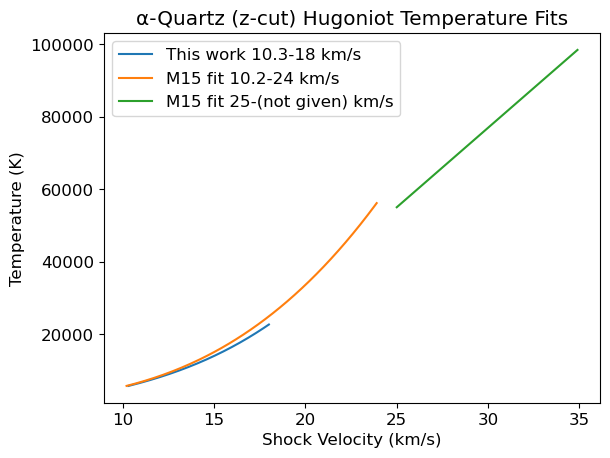

In [22]:

us_m15 = np.arange(10.2,24,0.1)
t_m15 = 1421.9+4.3185*np.pow(us_m15,2.9768)
us_m15b = np.arange(25,35,0.1)
t_m15b = -54567+4384.6*us_m15b

ind = np.where((qtz_hug_liq.us>10.3) & (qtz_hug_liq.us<18))[0]
plt.plot(qtz_hug_liq.us[ind],qtz_hug_liq.T[ind],label='This work 10.3-18 km/s')
plt.plot(us_m15,t_m15,label='M15 fit 10.2-24 km/s')
plt.plot(us_m15b,t_m15b,label='M15 fit 25-(not given) km/s')

plt.xlabel('Shock Velocity (km/s)')
plt.ylabel('Temperature (K)')
plt.title('α-Quartz (z-cut) Hugoniot Temperature Fits')
plt.legend()
plt.show()

## Check consistency between EOS and Hugoniot Fits

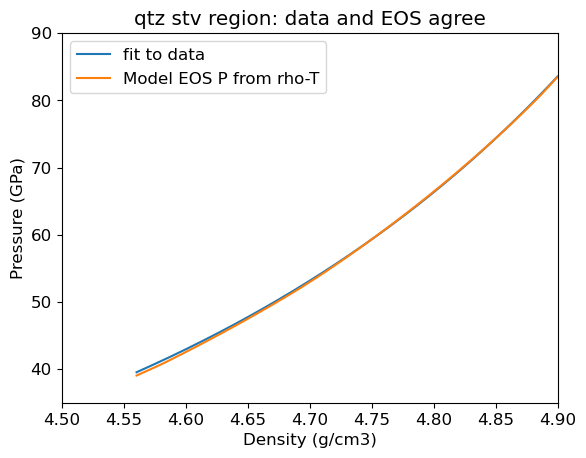

In [23]:
# check T(P,rho) model vs. data

pmodel=[]
for iii in range(len(qtz_hug_stv.T)):
    stvpvt.isotherm_stv(qtz_hug_stv.T[iii])
    pmodel.append(np.interp(qtz_hug_stv.rho[iii],stvpvt.rhoarr,stvpvt.isotherm_p))


plt.plot(qtz_hug_stv.rho,qtz_hug_stv.P,label='fit to data')
plt.plot(qtz_hug_stv.rho,pmodel,label='Model EOS P from rho-T')
plt.title('qtz stv region: data and EOS agree')
plt.legend()
plt.ylim(35,90)
plt.xlim(4.5,4.9)
plt.xlabel('Density (g/cm3)')
plt.ylabel('Pressure (GPa)')
plt.savefig(outputfigpath+'qtz-stv-test.pdf')
plt.show()


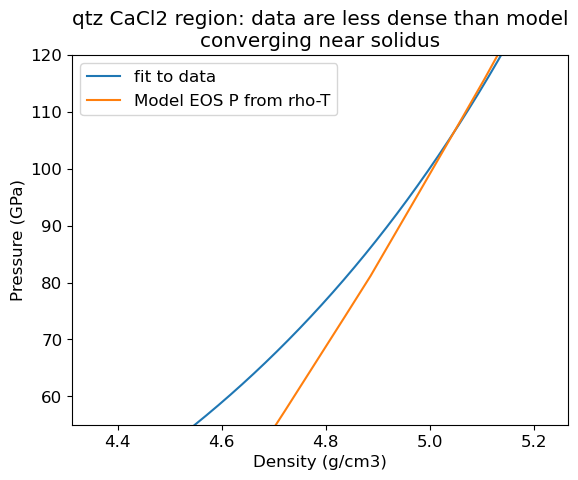

In [24]:
pmodel=[]
for iii in range(len(qtz_hug_cacl2.T)):
    stvpvt.isotherm_stv(qtz_hug_cacl2.T[iii])
    pmodel.append(np.interp(qtz_hug_cacl2.rho[iii],stvpvt.rhoarr,stvpvt.isotherm_p))


plt.plot(qtz_hug_cacl2.rho,qtz_hug_cacl2.P,label='fit to data')
plt.plot(qtz_hug_cacl2.rho,pmodel,label='Model EOS P from rho-T')
plt.title('qtz CaCl2 region: data are less dense than model\nconverging near solidus')
plt.ylim(55,120)
plt.legend()
plt.xlabel('Density (g/cm3)')
plt.ylabel('Pressure (GPa)')
plt.savefig(outputfigpath+'qtz-cacl2-test.pdf')
plt.show()


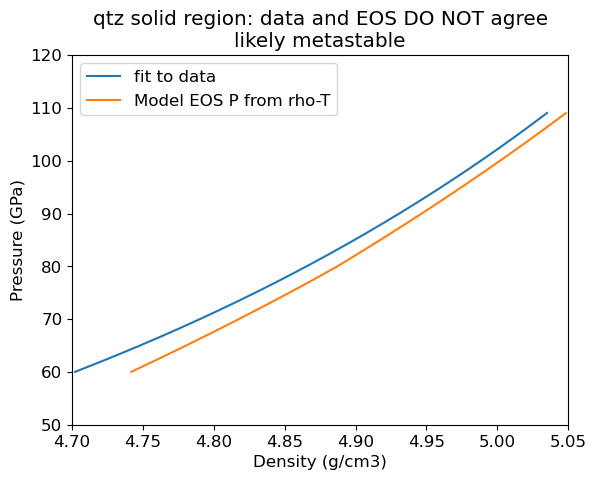

In [25]:
# check T(P,rho) model vs. data

pmodel=[]
for iii in range(len(qtz_hug_solid.T)):
    stvpvt.isotherm_stv(qtz_hug_solid.T[iii])
    pmodel.append(np.interp(qtz_hug_solid.rho[iii],stvpvt.rhoarr,stvpvt.isotherm_p))
pmodel=np.asarray(pmodel)
ind = np.where((qtz_hug_solid.P > 60) & (qtz_hug_solid.P < qtz_wiggle_P1))[0]
plt.plot(qtz_hug_solid.rho[ind],qtz_hug_solid.P[ind],label='fit to data')
ind = np.where((pmodel > 60) & (pmodel < qtz_wiggle_P1))[0]
plt.plot(qtz_hug_solid.rho[ind],pmodel[ind],label='Model EOS P from rho-T')
plt.title('qtz solid region: data and EOS DO NOT agree\nlikely metastable')
plt.legend()
plt.ylim(50,120)
plt.xlim(4.7,5.05)
plt.xlabel('Density (g/cm3)')
plt.ylabel('Pressure (GPa)')
plt.savefig(outputfigpath+'qtz-solid-test.pdf')
plt.show()
